## 9. Unimodal Baseline Implementation

### 9.1. Load Cached Features and Cross-Validation Folds

This task loads the cached DistilBERT and CLIP embeddings,
multi-label targets, and saved five-fold GroupKFold splits.

The same cross-validation folds will be used for all models
to ensure fair comparisons. The independent test set is
reserved for final evaluation.

In [2]:
import numpy as np
import torch
from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Multi Modal - Project 2.2"
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load cached embeddings
X_text = np.load(
    PROJECT_DIR / "text_embeddings.npy",
    mmap_mode="r"
)

X_image = np.load(
    PROJECT_DIR / "image_embeddings.npy",
    mmap_mode="r"
)

# Load multi-label targets
records = np.load(
    PROJECT_DIR / "data.npy",
    allow_pickle=True
)

y = np.stack(records[:, 1]).astype(np.float32)

# Load duplicate-group IDs
group_ids = np.load(PROJECT_DIR / "group_ids.npy")

# Load cross-validation folds
with np.load(PROJECT_DIR / "cv_fold_indices.npz") as cv:
    dev_idx = cv["dev_idx"].copy()
    test_idx = cv["test_idx"].copy()

    cv_folds = [
        (
            cv[f"fold_{k}_train_idx"].copy(),
            cv[f"fold_{k}_val_idx"].copy()
        )
        for k in range(1, 6)
    ]

# Validate data
assert X_text.shape == (25959, 768)
assert X_image.shape == (25959, 768)
assert y.shape == (25959, 23)
assert len(group_ids) == 25959
assert np.isin(y, [0, 1]).all()

assert np.intersect1d(
    group_ids[dev_idx], group_ids[test_idx]
).size == 0

for train_idx, val_idx in cv_folds:
    assert np.intersect1d(
        group_ids[train_idx], group_ids[val_idx]
    ).size == 0

print("Device:", device)
print("Text features:", X_text.shape)
print("Image features:", X_image.shape)
print("Genre labels:", y.shape)
print("Development records:", len(dev_idx))
print("Test records:", len(test_idx))
print("CV folds:", len(cv_folds))

print("\nData loading and validation: PASSED")

Mounted at /content/drive
Device: cpu
Text features: (25959, 768)
Image features: (25959, 768)
Genre labels: (25959, 23)
Development records: 18176
Test records: 7783
CV folds: 5

Data loading and validation: PASSED


### 9.2. Define Unimodal MLP Architecture

Two unimodal baseline classifiers are implemented using
the same Multi-Layer Perceptron (MLP) architecture.

Each classifier consists of:
- Input layer: 768-dimensional pretrained embeddings
- Hidden layer: 256 neurons with ReLU activation
- Dropout: 0.3 for regularisation
- Output layer: 23 genre logits

The models produce independent logits for each genre,
supporting multi-label classification with
BCEWithLogitsLoss during training.

Using identical classifier architectures enables a fair
comparison between text and image representations.

In [3]:
import torch
import torch.nn as nn
import numpy as np

# Set random seed for reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Model configuration
INPUT_DIM = 768
HIDDEN_DIM = 256
NUM_LABELS = 23
DROPOUT = 0.3

class UnimodalMLP(nn.Module):
    def __init__(
        self,
        input_dim=INPUT_DIM,
        hidden_dim=HIDDEN_DIM,
        num_labels=NUM_LABELS,
        dropout=DROPOUT
    ):
        super().__init__()

        self.classifier = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_labels)
        )

    def forward(self, x):
        return self.classifier(x)


# Initialise two baseline models
text_model = UnimodalMLP().to(device)
image_model = UnimodalMLP().to(device)

# Count trainable parameters
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print("Text-only MLP:")
print(text_model)

print("\nImage-only MLP:")
print(image_model)

print("\nModel Parameters:")
print("Text-only:", count_parameters(text_model))
print("Image-only:", count_parameters(image_model))
print("Device:", device)

Text-only MLP:
UnimodalMLP(
  (classifier): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=23, bias=True)
  )
)

Image-only MLP:
UnimodalMLP(
  (classifier): Sequential(
    (0): Linear(in_features=768, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=23, bias=True)
  )
)

Model Parameters:
Text-only: 202775
Image-only: 202775
Device: cpu


In [4]:
# Prepare small feature batches
sample_text = torch.tensor(
    np.asarray(X_text[:8]).copy(),
    dtype=torch.float32,
    device=device
)

sample_image = torch.tensor(
    np.asarray(X_image[:8]).copy(),
    dtype=torch.float32,
    device=device
)

# Evaluation mode for testing
text_model.eval()
image_model.eval()

# Test forward pass
with torch.no_grad():
    text_logits = text_model(sample_text)
    image_logits = image_model(sample_image)

# Verify output dimensions
assert text_logits.shape == (8, 23)
assert image_logits.shape == (8, 23)

assert torch.isfinite(text_logits).all()
assert torch.isfinite(image_logits).all()

print("Text input:", tuple(sample_text.shape))
print("Image input:", tuple(sample_image.shape))

print("Text output:", tuple(text_logits.shape))
print("Image output:", tuple(image_logits.shape))

print("\nBoth unimodal MLP forward passes: PASSED")

Text input: (8, 768)
Image input: (8, 768)
Text output: (8, 23)
Image output: (8, 23)

Both unimodal MLP forward passes: PASSED


### 9.3. Configure Training and Evaluation

The unimodal classifiers are trained using binary
cross-entropy with logits and the Adam optimizer.

A group-aware internal validation split is created
within each outer training fold for early stopping.

Outer validation folds are reserved for performance
evaluation, preventing model selection leakage.

A fixed decision threshold of 0.5 is used initially
for all models to ensure consistent comparisons.

Macro F1 is the primary evaluation metric, supported
by Micro F1, Precision, and Recall.

In [5]:
import random
import numpy as np
import torch

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score
)

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Training configuration
LEARNING_RATE = 1e-3
BATCH_SIZE = 256
MAX_EPOCHS = 20
PATIENCE = 4
THRESHOLD = 0.5

# Internal validation split
INNER_VAL_SIZE = 0.10


def create_inner_split(outer_train_idx, seed=SEED):
    """
    Create a group-aware internal validation set
    within an outer cross-validation training fold.
    """

    splitter = GroupShuffleSplit(
        n_splits=1,
        test_size=INNER_VAL_SIZE,
        random_state=seed
    )

    train_pos, inner_val_pos = next(
        splitter.split(
            np.zeros(len(outer_train_idx)),
            groups=group_ids[outer_train_idx]
        )
    )

    fit_idx = outer_train_idx[train_pos]
    inner_val_idx = outer_train_idx[inner_val_pos]

    # Prevent duplicate-group leakage
    overlap = np.intersect1d(
        group_ids[fit_idx],
        group_ids[inner_val_idx]
    )

    assert len(overlap) == 0

    return fit_idx, inner_val_idx


def calculate_metrics(y_true, y_prob, threshold=THRESHOLD):
    """
    Calculate multi-label classification metrics.
    """

    y_pred = (y_prob >= threshold).astype(int)

    return {
        "Macro F1": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Micro F1": f1_score(
            y_true, y_pred,
            average="micro",
            zero_division=0
        ),
        "Macro Precision": precision_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, y_pred,
            average="macro",
            zero_division=0
        )
    }


# Verify internal splitting on Fold 1
outer_train_idx, outer_val_idx = cv_folds[0]

fit_idx, inner_val_idx = create_inner_split(
    outer_train_idx
)

# Verify all three groups are isolated
assert np.intersect1d(
    group_ids[fit_idx],
    group_ids[outer_val_idx]
).size == 0

assert np.intersect1d(
    group_ids[inner_val_idx],
    group_ids[outer_val_idx]
).size == 0

print("Training configuration:")
print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Early stopping patience:", PATIENCE)
print("Decision threshold:", THRESHOLD)

print("\nFold 1 data partition:")
print("Model training:", len(fit_idx))
print("Inner validation:", len(inner_val_idx))
print("Outer validation:", len(outer_val_idx))

print("\nInternal group-aware splitting: PASSED")

Training configuration:
Learning rate: 0.001
Batch size: 256
Maximum epochs: 20
Early stopping patience: 4
Decision threshold: 0.5

Fold 1 data partition:
Model training: 13085
Inner validation: 1455
Outer validation: 3636

Internal group-aware splitting: PASSED


### 9.4. Train Text-only Baseline

#### 9.4.1. Train and Evaluate Fold 1

A text-only MLP classifier is trained using cached
DistilBERT embeddings.

Standardisation is fitted exclusively on the model
training subset to prevent data leakage.

Early stopping uses the internal validation loss.
The outer validation set is used only after model
selection to evaluate generalisation.

The best-performing model, scaler, training history,
and out-of-fold predictions are saved for subsequent
comparison and late fusion.

In [6]:
import copy
import json
import joblib
import pandas as pd
import numpy as np
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

# Set reproducible seed
torch.manual_seed(SEED + 1)
np.random.seed(SEED + 1)

# Select Fold 1
outer_train_idx, outer_val_idx = cv_folds[0]

# Create internal group-aware split
fit_idx, inner_val_idx = create_inner_split(
    outer_train_idx
)

# Standardise features using training data only
scaler = StandardScaler()

X_fit = scaler.fit_transform(
    np.asarray(X_text[fit_idx])
).astype(np.float32)

X_inner = scaler.transform(
    np.asarray(X_text[inner_val_idx])
).astype(np.float32)

X_outer = scaler.transform(
    np.asarray(X_text[outer_val_idx])
).astype(np.float32)

# Prepare training dataset
train_dataset = TensorDataset(
    torch.from_numpy(X_fit),
    torch.from_numpy(y[fit_idx].copy())
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# Prepare validation tensors
x_inner = torch.from_numpy(X_inner).to(device)
y_inner = torch.from_numpy(
    y[inner_val_idx].copy()
).to(device)

# Initialise a fresh model
model = UnimodalMLP().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

# Early stopping configuration
best_loss = float("inf")
best_epoch = 0
best_state = None
patience_counter = 0
history = []

print("Training Text-only MLP — Fold 1\n")

for epoch in range(1, MAX_EPOCHS + 1):

    model.train()
    total_loss = 0.0

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(batch_x)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_x)

    train_loss = total_loss / len(train_dataset)

    # Internal validation
    model.eval()

    with torch.inference_mode():
        inner_logits = model(x_inner)
        inner_loss = criterion(
            inner_logits, y_inner
        ).item()

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "inner_val_loss": inner_loss
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Inner Val Loss: {inner_loss:.4f}"
    )

    # Save best weights
    if inner_loss < best_loss - 1e-4:

        best_loss = inner_loss
        best_epoch = epoch
        best_state = copy.deepcopy(
            model.state_dict()
        )
        patience_counter = 0

    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("\nEarly stopping triggered.")
            break

# Restore best model
model.load_state_dict(best_state)
model.eval()

# Evaluate training and outer validation performance
with torch.inference_mode():

    train_probs = torch.sigmoid(
        model(torch.from_numpy(X_fit).to(device))
    ).cpu().numpy()

    outer_probs = torch.sigmoid(
        model(torch.from_numpy(X_outer).to(device))
    ).cpu().numpy()

train_metrics = calculate_metrics(
    y[fit_idx], train_probs
)

outer_metrics = calculate_metrics(
    y[outer_val_idx], outer_probs
)

# Save outputs for reproducibility
RESULT_DIR = PROJECT_DIR / "results" / "text_only"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

torch.save(
    best_state,
    RESULT_DIR / "fold_1_model.pt"
)

joblib.dump(
    scaler,
    RESULT_DIR / "fold_1_scaler.joblib"
)

pd.DataFrame(history).to_csv(
    RESULT_DIR / "fold_1_history.csv",
    index=False
)

np.savez_compressed(
    RESULT_DIR / "fold_1_predictions.npz",
    indices=outer_val_idx,
    y_true=y[outer_val_idx],
    y_prob=outer_probs
)

# Display final results
print("\n--- Fold 1 Results ---")
print("Best epoch:", best_epoch)
print("Best inner validation loss:", round(best_loss, 4))

print("\nTraining metrics:")
for metric, value in train_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nOuter validation metrics:")
for metric, value in outer_metrics.items():
    print(f"{metric}: {value:.4f}")

print(
    "\nMacro F1 train-validation gap:",
    round(
        train_metrics["Macro F1"]
        - outer_metrics["Macro F1"],
        4
    )
)

print("\nText-only Fold 1 training: COMPLETED")

Training Text-only MLP — Fold 1

Epoch 01 | Train Loss: 0.2876 | Inner Val Loss: 0.1917
Epoch 02 | Train Loss: 0.1903 | Inner Val Loss: 0.1811
Epoch 03 | Train Loss: 0.1801 | Inner Val Loss: 0.1771
Epoch 04 | Train Loss: 0.1747 | Inner Val Loss: 0.1759
Epoch 05 | Train Loss: 0.1707 | Inner Val Loss: 0.1754
Epoch 06 | Train Loss: 0.1672 | Inner Val Loss: 0.1754
Epoch 07 | Train Loss: 0.1643 | Inner Val Loss: 0.1743
Epoch 08 | Train Loss: 0.1618 | Inner Val Loss: 0.1734
Epoch 09 | Train Loss: 0.1597 | Inner Val Loss: 0.1741
Epoch 10 | Train Loss: 0.1579 | Inner Val Loss: 0.1745
Epoch 11 | Train Loss: 0.1553 | Inner Val Loss: 0.1741
Epoch 12 | Train Loss: 0.1537 | Inner Val Loss: 0.1748

Early stopping triggered.

--- Fold 1 Results ---
Best epoch: 8
Best inner validation loss: 0.1734

Training metrics:
Macro F1: 0.5790
Micro F1: 0.6726
Macro Precision: 0.8088
Macro Recall: 0.4833

Outer validation metrics:
Macro F1: 0.5089
Micro F1: 0.6220
Macro Precision: 0.7154
Macro Recall: 0.4233

Ma

#### 9.4.2. Complete Text-only 5-Fold Cross-Validation

The same training configuration is applied to the
remaining four folds.

Each fold uses a freshly initialised classifier and
a scaler fitted only on its internal training partition.

Model selection is performed using inner validation
loss, while outer validation remains independent.

Fold-level checkpoints, predictions and metrics are
saved for reproducible model comparison.

In [34]:
import copy
import random
import joblib
import pandas as pd
import numpy as np
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

RESULT_DIR = PROJECT_DIR / "results" / "text_only"
RESULT_DIR.mkdir(parents=True, exist_ok=True)


def train_text_fold(fold_number):

    random.seed(SEED + fold_number)
    np.random.seed(SEED + fold_number)
    torch.manual_seed(SEED + fold_number)

    outer_train_idx, outer_val_idx = cv_folds[fold_number - 1]

    # Create group-aware internal split
    fit_idx, inner_val_idx = create_inner_split(
        outer_train_idx
    )

    # Fit scaler on training data only
    scaler = StandardScaler()

    X_fit = scaler.fit_transform(
        np.asarray(X_text[fit_idx])
    ).astype(np.float32)

    X_inner = scaler.transform(
        np.asarray(X_text[inner_val_idx])
    ).astype(np.float32)

    X_outer = scaler.transform(
        np.asarray(X_text[outer_val_idx])
    ).astype(np.float32)

    # Prepare tensors
    train_dataset = TensorDataset(
        torch.from_numpy(X_fit),
        torch.from_numpy(y[fit_idx].copy())
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    x_inner = torch.from_numpy(X_inner).to(device)
    y_inner = torch.from_numpy(
        y[inner_val_idx].copy()
    ).to(device)

    # Fresh model for each fold
    model = UnimodalMLP().to(device)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    patience_counter = 0
    history = []

    print(f"\n--- Training Fold {fold_number} ---")

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()
        total_loss = 0.0

        for batch_x, batch_y in train_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(batch_x)

        train_loss = total_loss / len(train_dataset)

        model.eval()
        with torch.inference_mode():
            inner_loss = criterion(
                model(x_inner), y_inner
            ).item()

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "inner_val_loss": inner_loss
        })

        if inner_loss < best_loss - 1e-4:
            best_loss = inner_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if patience_counter >= PATIENCE:
            break

    # Restore best model
    model.load_state_dict(best_state)
    model.eval()

    with torch.inference_mode():

        train_probs = torch.sigmoid(
            model(torch.from_numpy(X_fit).to(device))
        ).cpu().numpy()

        outer_probs = torch.sigmoid(
            model(torch.from_numpy(X_outer).to(device))
        ).cpu().numpy()

    train_metrics = calculate_metrics(
        y[fit_idx], train_probs
    )

    outer_metrics = calculate_metrics(
        y[outer_val_idx], outer_probs
    )

    # Save model, scaler and predictions
    torch.save(
        best_state,
        RESULT_DIR / f"fold_{fold_number}_model.pt"
    )

    joblib.dump(
        scaler,
        RESULT_DIR / f"fold_{fold_number}_scaler.joblib"
    )

    pd.DataFrame(history).to_csv(
        RESULT_DIR / f"fold_{fold_number}_history.csv",
        index=False
    )

    np.savez_compressed(
        RESULT_DIR / f"fold_{fold_number}_predictions.npz",
        indices=outer_val_idx,
        y_true=y[outer_val_idx],
        y_prob=outer_probs
    )

    print("Best epoch:", best_epoch)
    print("Best inner loss:", round(best_loss, 4))
    print("Train Macro F1:", round(train_metrics["Macro F1"], 4))
    print("Outer Macro F1:", round(outer_metrics["Macro F1"], 4))
    print("Outer Micro F1:", round(outer_metrics["Micro F1"], 4))
    print(f"Fold {fold_number}: COMPLETED")

for fold_number in range(2, 6):
    train_text_fold(fold_number)

print("\nAll remaining text-only folds completed.")


--- Training Fold 2 ---
Best epoch: 7
Best inner loss: 0.1781
Train Macro F1: 0.5699
Outer Macro F1: 0.5175
Outer Micro F1: 0.6144
Fold 2: COMPLETED

--- Training Fold 3 ---
Best epoch: 8
Best inner loss: 0.177
Train Macro F1: 0.5792
Outer Macro F1: 0.5099
Outer Micro F1: 0.6182
Fold 3: COMPLETED

--- Training Fold 4 ---
Best epoch: 10
Best inner loss: 0.1737
Train Macro F1: 0.5981
Outer Macro F1: 0.5186
Outer Micro F1: 0.6151
Fold 4: COMPLETED

--- Training Fold 5 ---
Best epoch: 8
Best inner loss: 0.1739
Train Macro F1: 0.5841
Outer Macro F1: 0.5184
Outer Micro F1: 0.6206
Fold 5: COMPLETED

All remaining text-only folds completed.


#### 9.4.3. Summarise Text-only Cross-Validation Results

The saved outer-fold predictions are loaded to calculate
the mean and standard deviation of evaluation metrics.

Out-of-fold predictions are combined in the original
dataset order for reproducible analysis.

All 18,176 development records must appear exactly once
in the outer validation predictions.

The independent test set remains untouched.

In [8]:
import numpy as np
import pandas as pd

RESULT_DIR = PROJECT_DIR / "results" / "text_only"

fold_results = []

# Original record index -> development position
dev_positions = np.full(len(y), -1, dtype=int)
dev_positions[dev_idx] = np.arange(len(dev_idx))

oof_probs = np.full(
    (len(dev_idx), y.shape[1]),
    np.nan,
    dtype=np.float32
)

coverage = np.zeros(len(dev_idx), dtype=int)

# Load saved results from all five folds
for fold in range(1, 6):

    prediction_path = (
        RESULT_DIR / f"fold_{fold}_predictions.npz"
    )

    with np.load(prediction_path) as saved:
        indices = saved["indices"]
        y_true = saved["y_true"]
        y_prob = saved["y_prob"]

    # Verify predictions match the saved CV fold
    expected_val_idx = cv_folds[fold - 1][1]

    assert np.array_equal(
        np.sort(indices),
        np.sort(expected_val_idx)
    )

    assert np.array_equal(y_true, y[indices])
    assert y_prob.shape == (len(indices), 23)
    assert np.isfinite(y_prob).all()

    # Calculate fold metrics
    metrics = calculate_metrics(
        y_true, y_prob, threshold=THRESHOLD
    )

    fold_results.append({
        "Fold": fold,
        **metrics
    })

    # Store out-of-fold predictions
    positions = dev_positions[indices]

    assert np.all(positions >= 0)

    oof_probs[positions] = y_prob
    coverage[positions] += 1

# Verify complete development coverage
assert np.all(coverage == 1)
assert np.isfinite(oof_probs).all()

# Create results table
results_df = pd.DataFrame(fold_results)

metric_columns = [
    "Macro F1",
    "Micro F1",
    "Macro Precision",
    "Macro Recall"
]

summary_df = pd.DataFrame({
    "Mean": results_df[metric_columns].mean(),
    "SD": results_df[metric_columns].std(ddof=1)
})

print("Text-only 5-Fold CV Results:\n")
print(results_df.round(4).to_string(index=False))

print("\nCross-Validation Summary:\n")
print(summary_df.round(4).to_string())

# Save results
results_df.to_csv(
    RESULT_DIR / "text_only_cv_results.csv",
    index=False
)

summary_df.to_csv(
    RESULT_DIR / "text_only_cv_summary.csv"
)

np.savez_compressed(
    RESULT_DIR / "text_only_oof_predictions.npz",
    indices=dev_idx,
    y_true=y[dev_idx],
    y_prob=oof_probs,
    threshold=THRESHOLD
)

print("\nAll five folds verified.")
print("OOF records:", len(dev_idx))
print("Text-only CV summary saved successfully.")

Text-only 5-Fold CV Results:

 Fold  Macro F1  Micro F1  Macro Precision  Macro Recall
    1    0.5089    0.6220           0.7154        0.4233
    2    0.5175    0.6144           0.7251        0.4263
    3    0.5099    0.6182           0.7296        0.4291
    4    0.5186    0.6151           0.7228        0.4368
    5    0.5184    0.6206           0.6756        0.4358

Cross-Validation Summary:

                   Mean      SD
Macro F1         0.5146  0.0048
Micro F1         0.6181  0.0033
Macro Precision  0.7137  0.0219
Macro Recall     0.4303  0.0059

All five folds verified.
OOF records: 18176
Text-only CV summary saved successfully.


### 9.5. Image-only Baseline Implementation

#### 9.5.1. Train and Evaluate Image-only Fold 1

An image-only MLP classifier is trained using cached
CLIP ViT-B/32 poster embeddings.

The same architecture, training configuration,
cross-validation folds, and evaluation metrics as the
text-only baseline are used for fair comparison.

Feature standardisation is fitted exclusively on the
internal training partition.

Early stopping is based on inner validation loss,
while the outer validation fold is reserved for
performance evaluation.

In [9]:
import copy
import random
import joblib
import pandas as pd
import numpy as np
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

# Image-only results directory
IMAGE_RESULT_DIR = PROJECT_DIR / "results" / "image_only"
IMAGE_RESULT_DIR.mkdir(parents=True, exist_ok=True)


def train_image_fold(fold_number):

    # Reproducibility
    random.seed(SEED + fold_number)
    np.random.seed(SEED + fold_number)
    torch.manual_seed(SEED + fold_number)

    # Select outer CV fold
    outer_train_idx, outer_val_idx = cv_folds[fold_number - 1]

    # Create internal group-aware validation split
    fit_idx, inner_val_idx = create_inner_split(
        outer_train_idx
    )

    # Standardise CLIP features using training data only
    scaler = StandardScaler()

    X_fit = scaler.fit_transform(
        np.asarray(X_image[fit_idx])
    ).astype(np.float32)

    X_inner = scaler.transform(
        np.asarray(X_image[inner_val_idx])
    ).astype(np.float32)

    X_outer = scaler.transform(
        np.asarray(X_image[outer_val_idx])
    ).astype(np.float32)

    # Prepare training dataset
    train_dataset = TensorDataset(
        torch.from_numpy(X_fit),
        torch.from_numpy(y[fit_idx].copy())
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    # Internal validation tensors
    x_inner = torch.from_numpy(X_inner).to(device)

    y_inner = torch.from_numpy(
        y[inner_val_idx].copy()
    ).to(device)

    # Initialise a fresh image-only MLP
    model = UnimodalMLP().to(device)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    # Early stopping configuration
    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    patience_counter = 0
    history = []

    print(f"\nTraining Image-only MLP - Fold {fold_number}")

    # Training loop
    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()
        total_loss = 0.0

        for batch_x, batch_y in train_loader:

            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad(set_to_none=True)

            logits = model(batch_x)
            loss = criterion(logits, batch_y)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(batch_x)

        train_loss = total_loss / len(train_dataset)

        # Evaluate internal validation loss
        model.eval()

        with torch.inference_mode():
            inner_loss = criterion(
                model(x_inner),
                y_inner
            ).item()

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "inner_val_loss": inner_loss
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Inner Val Loss: {inner_loss:.4f}"
        )

        # Early stopping
        if inner_loss < best_loss - 1e-4:

            best_loss = inner_loss
            best_epoch = epoch
            best_state = copy.deepcopy(
                model.state_dict()
            )
            patience_counter = 0

        else:
            patience_counter += 1

            if patience_counter >= PATIENCE:
                print("\nEarly stopping triggered.")
                break

    # Restore best model
    model.load_state_dict(best_state)
    model.eval()

    # Evaluate training and outer validation
    with torch.inference_mode():

        train_probs = torch.sigmoid(
            model(torch.from_numpy(X_fit).to(device))
        ).cpu().numpy()

        outer_probs = torch.sigmoid(
            model(torch.from_numpy(X_outer).to(device))
        ).cpu().numpy()

    train_metrics = calculate_metrics(
        y[fit_idx], train_probs
    )

    outer_metrics = calculate_metrics(
        y[outer_val_idx], outer_probs
    )

    # Save model checkpoint
    torch.save(
        best_state,
        IMAGE_RESULT_DIR / f"fold_{fold_number}_model.pt"
    )

    # Save scaler
    joblib.dump(
        scaler,
        IMAGE_RESULT_DIR / f"fold_{fold_number}_scaler.joblib"
    )

    # Save training history
    pd.DataFrame(history).to_csv(
        IMAGE_RESULT_DIR / f"fold_{fold_number}_history.csv",
        index=False
    )

    # Save outer validation predictions
    np.savez_compressed(
        IMAGE_RESULT_DIR / f"fold_{fold_number}_predictions.npz",
        indices=outer_val_idx,
        y_true=y[outer_val_idx],
        y_prob=outer_probs
    )

    # Display results
    print(f"\n--- Image-only Fold {fold_number} Results ---")
    print("Best epoch:", best_epoch)
    print("Best inner validation loss:", round(best_loss, 4))

    print("\nTraining metrics:")
    for name, value in train_metrics.items():
        print(f"{name}: {value:.4f}")

    print("\nOuter validation metrics:")
    for name, value in outer_metrics.items():
        print(f"{name}: {value:.4f}")

    print(
        "\nMacro F1 train-validation gap:",
        round(
            train_metrics["Macro F1"]
            - outer_metrics["Macro F1"],
            4
        )
    )

    print(f"\nImage-only Fold {fold_number}: COMPLETED")


# Test the image-only training pipeline on Fold 1
train_image_fold(1)


Training Image-only MLP - Fold 1
Epoch 01 | Train Loss: 0.3513 | Inner Val Loss: 0.2609
Epoch 02 | Train Loss: 0.2568 | Inner Val Loss: 0.2533
Epoch 03 | Train Loss: 0.2451 | Inner Val Loss: 0.2503
Epoch 04 | Train Loss: 0.2374 | Inner Val Loss: 0.2493
Epoch 05 | Train Loss: 0.2314 | Inner Val Loss: 0.2503
Epoch 06 | Train Loss: 0.2257 | Inner Val Loss: 0.2507
Epoch 07 | Train Loss: 0.2213 | Inner Val Loss: 0.2519
Epoch 08 | Train Loss: 0.2164 | Inner Val Loss: 0.2533

Early stopping triggered.

--- Image-only Fold 1 Results ---
Best epoch: 4
Best inner validation loss: 0.2493

Training metrics:
Macro F1: 0.1840
Micro F1: 0.4258
Macro Precision: 0.6204
Macro Recall: 0.1342

Outer validation metrics:
Macro F1: 0.1364
Micro F1: 0.3754
Macro Precision: 0.3335
Macro Recall: 0.1018

Macro F1 train-validation gap: 0.0476

Image-only Fold 1: COMPLETED


#### 9.5.2. Complete Image-only 5-Fold Cross-Validation

The image-only MLP is trained on the remaining four
cross-validation folds using the same architecture,
hyperparameters, and group-aware validation protocol.

Each fold uses a freshly initialised classifier.
Model checkpoints, scalers, training histories, and
outer-fold predictions are saved for later comparison.

The results will be used to assess model stability
and generalisation across different data partitions.

In [10]:
# Complete Image-only 5-Fold Cross-Validation

# Fold 1 has already been trained and saved
for fold_number in range(2, 6):
    train_image_fold(fold_number)

print("\nAll five Image-only CV folds completed.")


Training Image-only MLP - Fold 2
Epoch 01 | Train Loss: 0.3548 | Inner Val Loss: 0.2657
Epoch 02 | Train Loss: 0.2571 | Inner Val Loss: 0.2581
Epoch 03 | Train Loss: 0.2456 | Inner Val Loss: 0.2563
Epoch 04 | Train Loss: 0.2377 | Inner Val Loss: 0.2557
Epoch 05 | Train Loss: 0.2319 | Inner Val Loss: 0.2555
Epoch 06 | Train Loss: 0.2262 | Inner Val Loss: 0.2575
Epoch 07 | Train Loss: 0.2212 | Inner Val Loss: 0.2576
Epoch 08 | Train Loss: 0.2174 | Inner Val Loss: 0.2592
Epoch 09 | Train Loss: 0.2125 | Inner Val Loss: 0.2611

Early stopping triggered.

--- Image-only Fold 2 Results ---
Best epoch: 5
Best inner validation loss: 0.2555

Training metrics:
Macro F1: 0.1971
Micro F1: 0.4491
Macro Precision: 0.6454
Macro Recall: 0.1429

Outer validation metrics:
Macro F1: 0.1575
Micro F1: 0.3905
Macro Precision: 0.3709
Macro Recall: 0.1180

Macro F1 train-validation gap: 0.0396

Image-only Fold 2: COMPLETED

Training Image-only MLP - Fold 3
Epoch 01 | Train Loss: 0.3557 | Inner Val Loss: 0.268

#### 9.5.3. Summarise Image-only Cross-Validation Results

The saved outer-fold predictions are loaded to calculate
the mean and standard deviation of evaluation metrics.

Out-of-fold predictions are combined in the original
dataset order to support fair comparisons with the
text-only baseline and subsequent late fusion experiments.

Every development record must appear exactly once in
the out-of-fold predictions.

The independent test set remains untouched.

In [11]:
import numpy as np
import pandas as pd

# Image-only results directory
IMAGE_RESULT_DIR = PROJECT_DIR / "results" / "image_only"

# Prepare result storage
fold_results = []

# Map original record indices to development positions
dev_positions = np.full(len(y), -1, dtype=int)
dev_positions[dev_idx] = np.arange(len(dev_idx))

# Initialise out-of-fold prediction matrix
image_oof_probs = np.full(
    (len(dev_idx), y.shape[1]),
    np.nan,
    dtype=np.float32
)

coverage = np.zeros(len(dev_idx), dtype=int)

# Load saved predictions from all five folds
for fold in range(1, 6):

    prediction_path = (
        IMAGE_RESULT_DIR / f"fold_{fold}_predictions.npz"
    )

    assert prediction_path.exists(), (
        f"Missing predictions for Fold {fold}"
    )

    with np.load(prediction_path) as saved:
        indices = saved["indices"].copy()
        y_true = saved["y_true"].copy()
        y_prob = saved["y_prob"].copy()

    # Verify alignment with saved CV fold
    expected_val_idx = cv_folds[fold - 1][1]

    assert np.array_equal(
        np.sort(indices),
        np.sort(expected_val_idx)
    )

    assert len(np.unique(indices)) == len(indices)
    assert np.array_equal(y_true, y[indices])
    assert y_prob.shape == (len(indices), 23)
    assert np.isfinite(y_prob).all()
    assert ((y_prob >= 0) & (y_prob <= 1)).all()

    # Calculate evaluation metrics
    metrics = calculate_metrics(
        y_true,
        y_prob,
        threshold=THRESHOLD
    )

    fold_results.append({
        "Fold": fold,
        **metrics
    })

    # Store out-of-fold predictions
    positions = dev_positions[indices]

    assert np.all(positions >= 0)
    assert np.all(coverage[positions] == 0)

    image_oof_probs[positions] = y_prob
    coverage[positions] += 1

# Verify complete development coverage
assert np.all(coverage == 1)
assert np.isfinite(image_oof_probs).all()

# Create fold-level results table
image_results_df = pd.DataFrame(fold_results)

metric_columns = [
    "Macro F1",
    "Micro F1",
    "Macro Precision",
    "Macro Recall"
]

# Calculate mean and sample standard deviation
image_summary_df = pd.DataFrame({
    "Mean": image_results_df[metric_columns].mean(),
    "SD": image_results_df[metric_columns].std(ddof=1)
})

# Display results
print("Image-only 5-Fold CV Results:\n")
print(image_results_df.round(4).to_string(index=False))

print("\nCross-Validation Summary:\n")
print(image_summary_df.round(4).to_string())

# Save fold-level metrics
image_results_df.to_csv(
    IMAGE_RESULT_DIR / "image_only_cv_results.csv",
    index=False
)

# Save CV summary
image_summary_df.to_csv(
    IMAGE_RESULT_DIR / "image_only_cv_summary.csv"
)

# Save out-of-fold predictions
np.savez_compressed(
    IMAGE_RESULT_DIR / "image_only_oof_predictions.npz",
    indices=dev_idx,
    y_true=y[dev_idx],
    y_prob=image_oof_probs,
    threshold=THRESHOLD
)

print("\nAll five folds verified.")
print("OOF records:", len(dev_idx))
print("Image-only CV summary saved successfully.")

Image-only 5-Fold CV Results:

 Fold  Macro F1  Micro F1  Macro Precision  Macro Recall
    1    0.1364    0.3754           0.3335        0.1018
    2    0.1575    0.3905           0.3709        0.1180
    3    0.1564    0.3869           0.3869        0.1184
    4    0.1468    0.3802           0.4303        0.1068
    5    0.1388    0.3777           0.4015        0.1042

Cross-Validation Summary:

                   Mean      SD
Macro F1         0.1472  0.0097
Micro F1         0.3821  0.0064
Macro Precision  0.3846  0.0360
Macro Recall     0.1098  0.0078

All five folds verified.
OOF records: 18176
Image-only CV summary saved successfully.


### 9.6. Compare Unimodal Baseline Performance

The DistilBERT text-only and CLIP image-only classifiers
are compared using identical five-fold GroupKFold splits.

The comparison includes Macro F1, Micro F1, Macro
Precision and Macro Recall, reported as mean and
standard deviation across outer validation folds.

Paired fold-level differences are calculated to assess
the relative effectiveness of each modality.

Both models use the same MLP architecture, training
protocol and fixed decision threshold of 0.5.

Unimodal Baseline Comparison:

         Metric  Text Mean  Text SD  Image Mean  Image SD  Difference
       Macro F1     0.5146   0.0048      0.1472    0.0097      0.3675
       Micro F1     0.6181   0.0033      0.3821    0.0064      0.2359
Macro Precision     0.7137   0.0219      0.3846    0.0360      0.3291
   Macro Recall     0.4303   0.0059      0.1098    0.0078      0.3204

Paired Fold Differences:

 Fold  Macro F1 Difference  Micro F1 Difference
    1               0.3724               0.2466
    2               0.3600               0.2238
    3               0.3535               0.2313
    4               0.3717               0.2349
    5               0.3796               0.2429


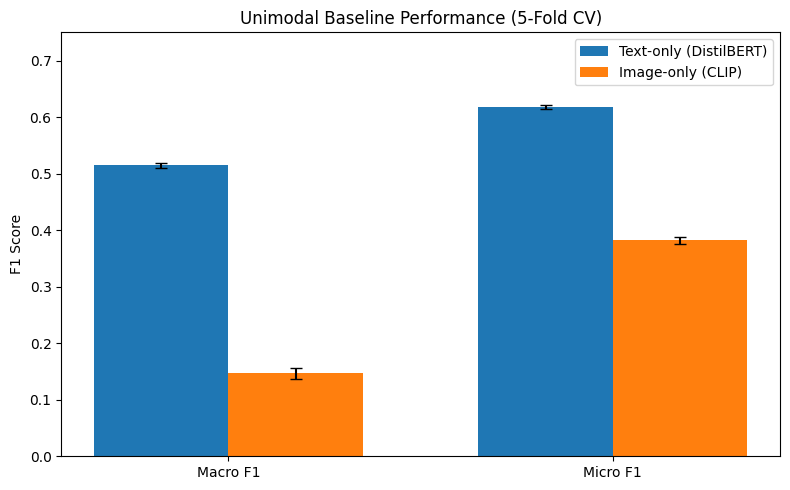


Unimodal comparison completed.
Results and figure saved successfully.


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load saved cross-validation results
text_df = pd.read_csv(
    PROJECT_DIR / "results/text_only/text_only_cv_results.csv"
).sort_values("Fold").reset_index(drop=True)

image_df = pd.read_csv(
    PROJECT_DIR / "results/image_only/image_only_cv_results.csv"
).sort_values("Fold").reset_index(drop=True)

# Verify identical folds
assert np.array_equal(
    text_df["Fold"].values,
    image_df["Fold"].values
)

metrics = [
    "Macro F1",
    "Micro F1",
    "Macro Precision",
    "Macro Recall"
]

# Calculate comparison statistics
comparison_rows = []

for metric in metrics:
    comparison_rows.append({
        "Metric": metric,
        "Text Mean": text_df[metric].mean(),
        "Text SD": text_df[metric].std(ddof=1),
        "Image Mean": image_df[metric].mean(),
        "Image SD": image_df[metric].std(ddof=1),
        "Difference": (
            text_df[metric].mean()
            - image_df[metric].mean()
        )
    })

comparison_df = pd.DataFrame(comparison_rows)

print("Unimodal Baseline Comparison:\n")
print(comparison_df.round(4).to_string(index=False))

# Calculate paired fold differences
paired_df = pd.DataFrame({
    "Fold": text_df["Fold"],
    "Macro F1 Difference": (
        text_df["Macro F1"] - image_df["Macro F1"]
    ),
    "Micro F1 Difference": (
        text_df["Micro F1"] - image_df["Micro F1"]
    )
})

print("\nPaired Fold Differences:\n")
print(paired_df.round(4).to_string(index=False))

# Create comparison figure
plot_metrics = ["Macro F1", "Micro F1"]
plot_data = comparison_df.set_index("Metric")

x = np.arange(len(plot_metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    x - width / 2,
    plot_data.loc[plot_metrics, "Text Mean"],
    width,
    yerr=plot_data.loc[plot_metrics, "Text SD"],
    capsize=4,
    label="Text-only (DistilBERT)"
)

ax.bar(
    x + width / 2,
    plot_data.loc[plot_metrics, "Image Mean"],
    width,
    yerr=plot_data.loc[plot_metrics, "Image SD"],
    capsize=4,
    label="Image-only (CLIP)"
)

ax.set_xticks(x)
ax.set_xticklabels(plot_metrics)
ax.set_ylabel("F1 Score")
ax.set_ylim(0, 0.75)
ax.set_title("Unimodal Baseline Performance (5-Fold CV)")
ax.legend()

plt.tight_layout()

# Save results for report
COMPARISON_DIR = PROJECT_DIR / "results/comparison"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    COMPARISON_DIR / "unimodal_comparison.csv",
    index=False
)

paired_df.to_csv(
    COMPARISON_DIR / "unimodal_fold_differences.csv",
    index=False
)

plt.savefig(
    COMPARISON_DIR / "unimodal_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nUnimodal comparison completed.")
print("Results and figure saved successfully.")

### 9.7. Classification Threshold Optimisation

#### 9.7.1. Inner-Validation Threshold Tuning

The initial unimodal baselines use a fixed classification
threshold of 0.5.

To investigate the low recall, a range of global decision
thresholds is evaluated using each fold's internal
validation set.

The threshold maximising inner-validation Macro F1 is
selected separately for each model and fold.

The selected threshold is then evaluated on the
corresponding outer validation fold.

This procedure avoids directly optimising thresholds
on the outer validation predictions.

In [13]:
import numpy as np
import pandas as pd
import torch
import joblib

from sklearn.metrics import f1_score

# Threshold candidates
THRESHOLD_GRID = np.round(
    np.arange(0.05, 0.501, 0.025), 3
)

# Compare both unimodal models
model_configs = {
    "Text-only": ("text_only", X_text),
    "Image-only": ("image_only", X_image)
}

tuning_results = []
sensitivity_results = []

for model_name, (folder, features) in model_configs.items():

    result_dir = PROJECT_DIR / "results" / folder

    print(f"\n===== {model_name} =====")

    for fold_number in range(1, 6):

        outer_train_idx, outer_val_idx = cv_folds[
            fold_number - 1
        ]

        # Recreate the original inner split
        fit_idx, inner_val_idx = create_inner_split(
            outer_train_idx
        )

        # Load saved training scaler
        scaler = joblib.load(
            result_dir /
            f"fold_{fold_number}_scaler.joblib"
        )

        # Restore trained MLP
        model = UnimodalMLP().to(device)

        state = torch.load(
            result_dir / f"fold_{fold_number}_model.pt",
            map_location=device,
            weights_only=True
        )

        model.load_state_dict(state)
        model.eval()

        # Prepare inner validation features
        X_inner = scaler.transform(
            np.asarray(features[inner_val_idx])
        ).astype(np.float32)

        x_inner = torch.from_numpy(X_inner).to(device)

        # Predict inner validation probabilities
        with torch.inference_mode():
            inner_probs = torch.sigmoid(
                model(x_inner)
            ).cpu().numpy()

        inner_true = y[inner_val_idx]

        # Evaluate candidate thresholds on inner validation
        inner_scores = []

        for threshold in THRESHOLD_GRID:

            predictions = (
                inner_probs >= threshold
            ).astype(int)

            score = f1_score(
                inner_true,
                predictions,
                average="macro",
                zero_division=0
            )

            inner_scores.append(score)

            sensitivity_results.append({
                "Model": model_name,
                "Fold": fold_number,
                "Threshold": threshold,
                "Inner Macro F1": score
            })

        # Select threshold using inner validation only
        best_position = int(np.argmax(inner_scores))
        best_threshold = float(
            THRESHOLD_GRID[best_position]
        )

        # Load previously saved outer predictions
        with np.load(
            result_dir /
            f"fold_{fold_number}_predictions.npz"
        ) as saved:

            indices = saved["indices"].copy()
            outer_true = saved["y_true"].copy()
            outer_probs = saved["y_prob"].copy()

        # Validate prediction alignment
        assert np.array_equal(
            np.sort(indices),
            np.sort(outer_val_idx)
        )

        assert np.array_equal(
            outer_true,
            y[indices]
        )

        # Original fixed-threshold performance
        fixed_metrics = calculate_metrics(
            outer_true,
            outer_probs,
            threshold=0.5
        )

        # Tuned-threshold outer evaluation
        tuned_metrics = calculate_metrics(
            outer_true,
            outer_probs,
            threshold=best_threshold
        )

        tuning_results.append({
            "Model": model_name,
            "Fold": fold_number,
            "Selected Threshold": best_threshold,
            "Inner Macro F1": max(inner_scores),
            "Outer Macro F1 (0.5)": fixed_metrics["Macro F1"],
            "Outer Macro F1 (Tuned)": tuned_metrics["Macro F1"],
            "Outer Micro F1 (Tuned)": tuned_metrics["Micro F1"],
            "Outer Precision (Tuned)": tuned_metrics["Macro Precision"],
            "Outer Recall (Tuned)": tuned_metrics["Macro Recall"]
        })

        print(
            f"Fold {fold_number}: "
            f"Threshold={best_threshold:.3f} | "
            f"Macro F1: {fixed_metrics['Macro F1']:.4f} "
            f"-> {tuned_metrics['Macro F1']:.4f}"
        )

# Summarise results
tuning_df = pd.DataFrame(tuning_results)
sensitivity_df = pd.DataFrame(sensitivity_results)

tuning_df["Macro F1 Improvement"] = (
    tuning_df["Outer Macro F1 (Tuned)"]
    - tuning_df["Outer Macro F1 (0.5)"]
)

summary = tuning_df.groupby("Model").agg(
    Mean_Threshold=("Selected Threshold", "mean"),
    Fixed_Macro_F1=("Outer Macro F1 (0.5)", "mean"),
    Tuned_Macro_F1=("Outer Macro F1 (Tuned)", "mean"),
    Tuned_Macro_F1_SD=("Outer Macro F1 (Tuned)", "std"),
    Tuned_Micro_F1=("Outer Micro F1 (Tuned)", "mean"),
    Mean_Improvement=("Macro F1 Improvement", "mean")
)

# Save results
TUNING_DIR = PROJECT_DIR / "results" / "threshold_tuning"
TUNING_DIR.mkdir(parents=True, exist_ok=True)

tuning_df.to_csv(
    TUNING_DIR / "threshold_tuning_results.csv",
    index=False
)

sensitivity_df.to_csv(
    TUNING_DIR / "inner_threshold_sensitivity.csv",
    index=False
)

summary.to_csv(
    TUNING_DIR / "threshold_tuning_summary.csv"
)

print("\n===== Threshold Tuning Summary =====")
print(summary.round(4).to_string())

print("\nThreshold tuning completed.")


===== Text-only =====
Fold 1: Threshold=0.200 | Macro F1: 0.5089 -> 0.5728
Fold 2: Threshold=0.275 | Macro F1: 0.5175 -> 0.5837
Fold 3: Threshold=0.225 | Macro F1: 0.5099 -> 0.5754
Fold 4: Threshold=0.250 | Macro F1: 0.5186 -> 0.5703
Fold 5: Threshold=0.200 | Macro F1: 0.5184 -> 0.5721

===== Image-only =====
Fold 1: Threshold=0.150 | Macro F1: 0.1364 -> 0.2804
Fold 2: Threshold=0.125 | Macro F1: 0.1575 -> 0.2955
Fold 3: Threshold=0.150 | Macro F1: 0.1564 -> 0.2959
Fold 4: Threshold=0.125 | Macro F1: 0.1468 -> 0.2815
Fold 5: Threshold=0.125 | Macro F1: 0.1388 -> 0.2948

===== Threshold Tuning Summary =====
            Mean_Threshold  Fixed_Macro_F1  Tuned_Macro_F1  Tuned_Macro_F1_SD  Tuned_Micro_F1  Mean_Improvement
Model                                                                                                          
Image-only           0.135          0.1472          0.2896             0.0079          0.4523            0.1424
Text-only            0.230          0.5146       

#### 9.7.2. Visualise Threshold Sensitivity

This task analyses the relationship between classification
thresholds and inner-validation Macro F1.

The effect of threshold optimisation is evaluated by
comparing fixed-threshold and tuned-threshold performance
on the outer validation folds.

All results are aggregated over five group-aware folds.

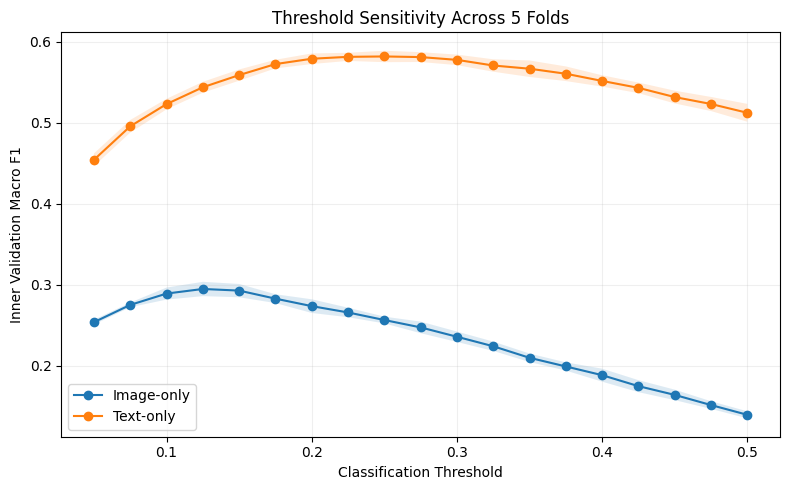

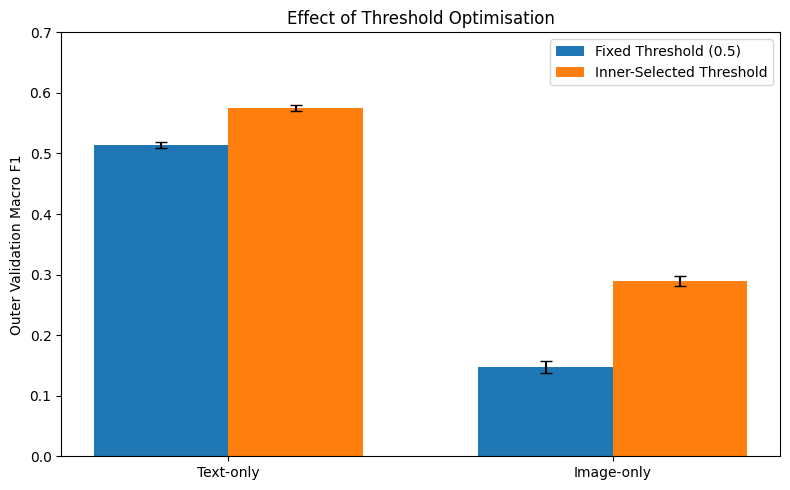

Threshold visualisations saved successfully.


In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load saved experimental results
TUNING_DIR = PROJECT_DIR / "results" / "threshold_tuning"

sensitivity_df = pd.read_csv(
    TUNING_DIR / "inner_threshold_sensitivity.csv"
)

tuning_df = pd.read_csv(
    TUNING_DIR / "threshold_tuning_results.csv"
)

# Figure 1: Threshold sensitivity
fig, ax = plt.subplots(figsize=(8, 5))

for model_name, data in sensitivity_df.groupby("Model"):

    stats = (
        data.groupby("Threshold")["Inner Macro F1"]
        .agg(["mean", "std"])
        .reset_index()
    )

    ax.plot(
        stats["Threshold"],
        stats["mean"],
        marker="o",
        label=model_name
    )

    ax.fill_between(
        stats["Threshold"],
        stats["mean"] - stats["std"],
        stats["mean"] + stats["std"],
        alpha=0.15
    )

ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Inner Validation Macro F1")
ax.set_title("Threshold Sensitivity Across 5 Folds")
ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    TUNING_DIR / "threshold_sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Figure 2: Fixed vs Tuned Macro F1
summary = tuning_df.groupby("Model").agg(
    Fixed_Mean=("Outer Macro F1 (0.5)", "mean"),
    Fixed_SD=("Outer Macro F1 (0.5)", "std"),
    Tuned_Mean=("Outer Macro F1 (Tuned)", "mean"),
    Tuned_SD=("Outer Macro F1 (Tuned)", "std")
)

models = ["Text-only", "Image-only"]
summary = summary.loc[models]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    x - width / 2,
    summary["Fixed_Mean"],
    width,
    yerr=summary["Fixed_SD"],
    capsize=4,
    label="Fixed Threshold (0.5)"
)

ax.bar(
    x + width / 2,
    summary["Tuned_Mean"],
    width,
    yerr=summary["Tuned_SD"],
    capsize=4,
    label="Inner-Selected Threshold"
)

ax.set_xticks(x)
ax.set_xticklabels(models)
ax.set_ylabel("Outer Validation Macro F1")
ax.set_ylim(0, 0.7)
ax.set_title("Effect of Threshold Optimisation")
ax.legend()

plt.tight_layout()
plt.savefig(
    TUNING_DIR / "threshold_optimisation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Threshold visualisations saved successfully.")

## 10. Multimodal Fusion Implementation

### 10.1. Define Early Fusion Architecture

Early fusion integrates text and image features before
classification, allowing the model to learn relationships
between the two modalities.

The frozen DistilBERT and CLIP Vision encoders produce
768-dimensional text and image embeddings, respectively.

The representations are concatenated into a
1536-dimensional vector and passed through a joint MLP
classifier with a 256-dimensional hidden layer,
ReLU activation, and dropout of 0.3.

Both modalities will be standardised separately using
statistics fitted only on the training partition.

The model produces 23 independent logits for
multi-label genre classification.

In [15]:
import numpy as np
import torch

# Early Fusion configuration
TEXT_DIM = X_text.shape[1]
IMAGE_DIM = X_image.shape[1]

FUSION_INPUT_DIM = TEXT_DIM + IMAGE_DIM

# Initialise Early Fusion MLP
early_fusion_model = UnimodalMLP(
    input_dim=FUSION_INPUT_DIM,
    hidden_dim=HIDDEN_DIM,
    num_labels=NUM_LABELS,
    dropout=DROPOUT
).to(device)

# Count trainable parameters
def count_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print("Early Fusion Architecture:")
print(early_fusion_model)

print("\nText dimensions:", TEXT_DIM)
print("Image dimensions:", IMAGE_DIM)
print("Fusion input dimensions:", FUSION_INPUT_DIM)
print("Output genres:", NUM_LABELS)

print(
    "Trainable parameters:",
    count_parameters(early_fusion_model)
)

print("Device:", device)

Early Fusion Architecture:
UnimodalMLP(
  (classifier): Sequential(
    (0): Linear(in_features=1536, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=23, bias=True)
  )
)

Text dimensions: 768
Image dimensions: 768
Fusion input dimensions: 1536
Output genres: 23
Trainable parameters: 399383
Device: cpu


In [16]:
# Select 8 aligned movie records
sample_text = np.asarray(X_text[:8])
sample_image = np.asarray(X_image[:8])

# Concatenate text and image features
sample_fusion = np.concatenate(
    [sample_text, sample_image],
    axis=1
).astype(np.float32)

# Convert to PyTorch tensor
fusion_tensor = torch.from_numpy(
    sample_fusion
).to(device)

# Test forward pass
early_fusion_model.eval()

with torch.inference_mode():
    fusion_logits = early_fusion_model(fusion_tensor)

# Validate dimensions and numerical values
assert sample_fusion.shape == (8, 1536)
assert fusion_logits.shape == (8, 23)
assert torch.isfinite(fusion_logits).all()

print("Text features:", sample_text.shape)
print("Image features:", sample_image.shape)
print("Combined features:", sample_fusion.shape)
print("Output logits:", tuple(fusion_logits.shape))

print("\nEarly Fusion forward pass: PASSED")

Text features: (8, 768)
Image features: (8, 768)
Combined features: (8, 1536)
Output logits: (8, 23)

Early Fusion forward pass: PASSED


### 10.2. Early Fusion Training

#### 10.2.1. Train and Evaluate Fold 1

The early fusion MLP combines standardised DistilBERT
and CLIP embeddings before classification.

Separate StandardScalers are fitted exclusively on the
internal training subset of each outer fold.

The model is trained using BCEWithLogitsLoss and Adam.
Early stopping is based on internal validation loss,
while the outer validation fold is reserved for evaluation.

The baseline uses a fixed threshold of 0.5. Trained
weights, scalers, training history and predictions are
saved for subsequent threshold optimisation and comparison.

In [17]:

import copy
import random
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset

# --------------------------------------------------
# 10.2.1. Early Fusion - Fold 1
# --------------------------------------------------

FOLD = 1

# Reproducibility
random.seed(SEED + FOLD)
np.random.seed(SEED + FOLD)
torch.manual_seed(SEED + FOLD)

# Create results directory
EARLY_RESULT_DIR = PROJECT_DIR / "results" / "early_fusion"
EARLY_RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Retrieve the original CV fold
outer_train_idx, outer_val_idx = cv_folds[FOLD - 1]

# Create group-aware internal validation split
fit_idx, inner_val_idx = create_inner_split(
    outer_train_idx
)

# Verify group isolation
assert np.intersect1d(
    group_ids[fit_idx],
    group_ids[inner_val_idx]
).size == 0

assert np.intersect1d(
    group_ids[outer_train_idx],
    group_ids[outer_val_idx]
).size == 0

# --------------------------------------------------
# 1. Standardise each modality independently
# --------------------------------------------------

text_scaler = StandardScaler()
image_scaler = StandardScaler()

# Fit scalers only on model training records
X_text_fit = text_scaler.fit_transform(
    np.asarray(X_text[fit_idx])
).astype(np.float32)

X_image_fit = image_scaler.fit_transform(
    np.asarray(X_image[fit_idx])
).astype(np.float32)

# Transform internal validation records
X_text_inner = text_scaler.transform(
    np.asarray(X_text[inner_val_idx])
).astype(np.float32)

X_image_inner = image_scaler.transform(
    np.asarray(X_image[inner_val_idx])
).astype(np.float32)

# Transform outer validation records
X_text_outer = text_scaler.transform(
    np.asarray(X_text[outer_val_idx])
).astype(np.float32)

X_image_outer = image_scaler.transform(
    np.asarray(X_image[outer_val_idx])
).astype(np.float32)

# --------------------------------------------------
# 2. Concatenate features
# --------------------------------------------------

X_fit = np.concatenate(
    [X_text_fit, X_image_fit], axis=1
)

X_inner = np.concatenate(
    [X_text_inner, X_image_inner], axis=1
)

X_outer = np.concatenate(
    [X_text_outer, X_image_outer], axis=1
)

assert X_fit.shape[1] == 1536
assert X_inner.shape[1] == 1536
assert X_outer.shape[1] == 1536

assert np.isfinite(X_fit).all()
assert np.isfinite(X_inner).all()
assert np.isfinite(X_outer).all()

print("Early Fusion feature preparation:")
print("Training:", X_fit.shape)
print("Inner validation:", X_inner.shape)
print("Outer validation:", X_outer.shape)

# --------------------------------------------------
# 3. Prepare datasets
# --------------------------------------------------

train_dataset = TensorDataset(
    torch.from_numpy(X_fit),
    torch.from_numpy(y[fit_idx].copy())
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

x_inner = torch.from_numpy(X_inner).to(device)
y_inner = torch.from_numpy(
    y[inner_val_idx].copy()
).to(device)

# --------------------------------------------------
# 4. Initialise a fresh Early Fusion MLP
# --------------------------------------------------

model = UnimodalMLP(
    input_dim=1536,
    hidden_dim=HIDDEN_DIM,
    num_labels=NUM_LABELS,
    dropout=DROPOUT
).to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

best_loss = float("inf")
best_epoch = 0
best_state = None
patience_counter = 0
history = []

print("\nTraining Early Fusion MLP - Fold 1\n")

# --------------------------------------------------
# 5. Training loop
# --------------------------------------------------

for epoch in range(1, MAX_EPOCHS + 1):

    model.train()
    total_loss = 0.0

    for batch_x, batch_y in train_loader:

        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)

        optimizer.zero_grad(set_to_none=True)

        logits = model(batch_x)
        loss = criterion(logits, batch_y)

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * len(batch_x)

    train_loss = total_loss / len(train_dataset)

    # Internal validation
    model.eval()

    with torch.inference_mode():
        inner_loss = criterion(
            model(x_inner),
            y_inner
        ).item()

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "inner_val_loss": inner_loss
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Inner Val Loss: {inner_loss:.4f}"
    )

    # Early stopping based on inner validation
    if inner_loss < best_loss - 1e-4:

        best_loss = inner_loss
        best_epoch = epoch
        best_state = copy.deepcopy(
            model.state_dict()
        )
        patience_counter = 0

    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("\nEarly stopping triggered.")
            break

# Restore best model
assert best_state is not None
model.load_state_dict(best_state)
model.eval()

# --------------------------------------------------
# 6. Evaluate trained model
# --------------------------------------------------

with torch.inference_mode():

    train_probs = torch.sigmoid(
        model(torch.from_numpy(X_fit).to(device))
    ).cpu().numpy()

    inner_probs = torch.sigmoid(
        model(torch.from_numpy(X_inner).to(device))
    ).cpu().numpy()

    outer_probs = torch.sigmoid(
        model(torch.from_numpy(X_outer).to(device))
    ).cpu().numpy()

train_metrics = calculate_metrics(
    y[fit_idx],
    train_probs,
    threshold=0.5
)

outer_metrics = calculate_metrics(
    y[outer_val_idx],
    outer_probs,
    threshold=0.5
)

# --------------------------------------------------
# 7. Save reproducible artifacts
# --------------------------------------------------

torch.save(
    best_state,
    EARLY_RESULT_DIR / "fold_1_model.pt"
)

joblib.dump(
    text_scaler,
    EARLY_RESULT_DIR / "fold_1_text_scaler.joblib"
)

joblib.dump(
    image_scaler,
    EARLY_RESULT_DIR / "fold_1_image_scaler.joblib"
)

pd.DataFrame(history).to_csv(
    EARLY_RESULT_DIR / "fold_1_history.csv",
    index=False
)

# Save internal validation predictions for tuning
np.savez_compressed(
    EARLY_RESULT_DIR / "fold_1_inner_predictions.npz",
    indices=inner_val_idx,
    y_true=y[inner_val_idx],
    y_prob=inner_probs
)

# Save outer validation predictions for evaluation
np.savez_compressed(
    EARLY_RESULT_DIR / "fold_1_predictions.npz",
    indices=outer_val_idx,
    y_true=y[outer_val_idx],
    y_prob=outer_probs
)

# --------------------------------------------------
# 8. Display results
# --------------------------------------------------

print("\n--- Early Fusion Fold 1 Results ---")

print("Best epoch:", best_epoch)
print("Best inner validation loss:", round(best_loss, 4))

print("\nTraining metrics:")
for metric, value in train_metrics.items():
    print(f"{metric}: {value:.4f}")

print("\nOuter validation metrics:")
for metric, value in outer_metrics.items():
    print(f"{metric}: {value:.4f}")

print(
    "\nMacro F1 train-validation gap:",
    round(
        train_metrics["Macro F1"]
        - outer_metrics["Macro F1"],
        4
    )
)

print("\nEarly Fusion Fold 1: COMPLETED")


Early Fusion feature preparation:
Training: (13085, 1536)
Inner validation: (1455, 1536)
Outer validation: (3636, 1536)

Training Early Fusion MLP - Fold 1

Epoch 01 | Train Loss: 0.2780 | Inner Val Loss: 0.1821
Epoch 02 | Train Loss: 0.1775 | Inner Val Loss: 0.1718
Epoch 03 | Train Loss: 0.1637 | Inner Val Loss: 0.1695
Epoch 04 | Train Loss: 0.1543 | Inner Val Loss: 0.1691
Epoch 05 | Train Loss: 0.1471 | Inner Val Loss: 0.1695
Epoch 06 | Train Loss: 0.1405 | Inner Val Loss: 0.1709
Epoch 07 | Train Loss: 0.1351 | Inner Val Loss: 0.1719
Epoch 08 | Train Loss: 0.1293 | Inner Val Loss: 0.1747

Early stopping triggered.

--- Early Fusion Fold 1 Results ---
Best epoch: 4
Best inner validation loss: 0.1691

Training metrics:
Macro F1: 0.6237
Micro F1: 0.7104
Macro Precision: 0.8439
Macro Recall: 0.5240

Outer validation metrics:
Macro F1: 0.5098
Micro F1: 0.6309
Macro Precision: 0.7028
Macro Recall: 0.4240

Macro F1 train-validation gap: 0.1139

Early Fusion Fold 1: COMPLETED


### 10.3. Early Fusion Five-Fold Cross-Validation

The Early Fusion MLP is trained independently on the
remaining four GroupKFold partitions.

For each fold, the text and image scalers are fitted
only on the internal training subset. A fresh MLP is
initialised and trained with early stopping based on
internal validation loss.

Predictions are saved separately for the inner and
outer validation sets to support threshold tuning
and unbiased outer-fold evaluation.

In [18]:

def train_early_fusion_fold(fold_number):

    # Reproducibility
    fold_seed = SEED + fold_number
    random.seed(fold_seed)
    np.random.seed(fold_seed)
    torch.manual_seed(fold_seed)

    result_dir = PROJECT_DIR / "results" / "early_fusion"
    result_dir.mkdir(parents=True, exist_ok=True)

    # Retrieve outer CV partition
    outer_train_idx, outer_val_idx = cv_folds[fold_number - 1]

    # Recreate the original inner split
    fit_idx, inner_val_idx = create_inner_split(
        outer_train_idx
    )

    # Verify no overlapping groups
    assert not np.intersect1d(
        group_ids[fit_idx], group_ids[inner_val_idx]
    ).size

    assert not np.intersect1d(
        group_ids[outer_train_idx], group_ids[outer_val_idx]
    ).size

    # Fit separate scalers on internal training data
    text_scaler = StandardScaler()
    image_scaler = StandardScaler()

    text_fit = text_scaler.fit_transform(
        np.asarray(X_text[fit_idx])
    )

    image_fit = image_scaler.fit_transform(
        np.asarray(X_image[fit_idx])
    )

    # Build fused features without data leakage
    X_fit = np.concatenate(
        [text_fit, image_fit], axis=1
    ).astype(np.float32)

    def transform_fusion(indices):
        text_features = text_scaler.transform(
            np.asarray(X_text[indices])
        )
        image_features = image_scaler.transform(
            np.asarray(X_image[indices])
        )
        return np.concatenate(
            [text_features, image_features], axis=1
        ).astype(np.float32)

    X_inner = transform_fusion(inner_val_idx)
    X_outer = transform_fusion(outer_val_idx)

    assert X_fit.shape[1] == 1536
    assert np.isfinite(X_fit).all()
    assert np.isfinite(X_inner).all()
    assert np.isfinite(X_outer).all()

    # Prepare training data
    train_loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_fit),
            torch.from_numpy(y[fit_idx].copy())
        ),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    x_inner = torch.from_numpy(X_inner).to(device)
    y_inner = torch.from_numpy(
        y[inner_val_idx].copy()
    ).to(device)

    # Initialise fresh model
    model = UnimodalMLP(
        input_dim=1536,
        hidden_dim=HIDDEN_DIM,
        num_labels=NUM_LABELS,
        dropout=DROPOUT
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    patience_counter = 0
    history = []

    print(f"\n===== Early Fusion Fold {fold_number} =====")

    # Training loop
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        total_loss = 0.0

        for batch_x, batch_y in train_loader:
            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad(set_to_none=True)

            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(batch_x)

        train_loss = total_loss / len(fit_idx)

        model.eval()
        with torch.inference_mode():
            inner_loss = criterion(
                model(x_inner), y_inner
            ).item()

        history.append({
            "epoch": epoch,
            "train_loss": train_loss,
            "inner_val_loss": inner_loss
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Train: {train_loss:.4f} | "
            f"Inner Val: {inner_loss:.4f}"
        )

        if inner_loss < best_loss - 1e-4:
            best_loss = inner_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

            if patience_counter >= PATIENCE:
                print("Early stopping triggered.")
                break

    # Restore selected checkpoint
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()

    # Batched inference, suitable for CPU
    def predict_probabilities(features):
        predictions = []

        for start in range(0, len(features), BATCH_SIZE):
            batch = torch.from_numpy(
                features[start:start + BATCH_SIZE]
            ).to(device)

            with torch.inference_mode():
                probabilities = torch.sigmoid(
                    model(batch)
                ).cpu().numpy()

            predictions.append(probabilities)

        return np.concatenate(predictions, axis=0)

    train_probs = predict_probabilities(X_fit)
    inner_probs = predict_probabilities(X_inner)
    outer_probs = predict_probabilities(X_outer)

    train_metrics = calculate_metrics(
        y[fit_idx], train_probs, threshold=0.5
    )

    outer_metrics = calculate_metrics(
        y[outer_val_idx], outer_probs, threshold=0.5
    )

    # Save checkpoint and preprocessing objects
    prefix = f"fold_{fold_number}"

    torch.save(
        best_state,
        result_dir / f"{prefix}_model.pt"
    )

    joblib.dump(
        text_scaler,
        result_dir / f"{prefix}_text_scaler.joblib"
    )

    joblib.dump(
        image_scaler,
        result_dir / f"{prefix}_image_scaler.joblib"
    )

    pd.DataFrame(history).to_csv(
        result_dir / f"{prefix}_history.csv",
        index=False
    )

    np.savez_compressed(
        result_dir / f"{prefix}_inner_predictions.npz",
        indices=inner_val_idx,
        y_true=y[inner_val_idx],
        y_prob=inner_probs
    )

    np.savez_compressed(
        result_dir / f"{prefix}_predictions.npz",
        indices=outer_val_idx,
        y_true=y[outer_val_idx],
        y_prob=outer_probs
    )

    print(f"\nFold {fold_number} Results:")
    print(f"Best epoch: {best_epoch}")
    print(f"Best inner validation loss: {best_loss:.4f}")

    print("\nTraining:")
    for name, value in train_metrics.items():
        print(f"{name}: {value:.4f}")

    print("\nOuter validation:")
    for name, value in outer_metrics.items():
        print(f"{name}: {value:.4f}")

    print(
        "\nMacro F1 train-validation gap:",
        round(
            train_metrics["Macro F1"]
            - outer_metrics["Macro F1"],
            4
        )
    )

    print(f"\nEarly Fusion Fold {fold_number}: COMPLETED")

    return {
        "Fold": fold_number,
        "Best Epoch": best_epoch,
        "Best Inner Loss": best_loss,
        **outer_metrics
    }


In [19]:
early_fusion_remaining_results = []

for fold_number in range(2, 6):
    result = train_early_fusion_fold(fold_number)
    early_fusion_remaining_results.append(result)

print("\n===== Early Fusion Folds 2-5 Summary =====")

print(
    pd.DataFrame(
        early_fusion_remaining_results
    ).round(4).to_string(index=False)
)


===== Early Fusion Fold 2 =====
Epoch 01 | Train: 0.2812 | Inner Val: 0.1872
Epoch 02 | Train: 0.1779 | Inner Val: 0.1782
Epoch 03 | Train: 0.1639 | Inner Val: 0.1766
Epoch 04 | Train: 0.1550 | Inner Val: 0.1764
Epoch 05 | Train: 0.1471 | Inner Val: 0.1764
Epoch 06 | Train: 0.1404 | Inner Val: 0.1770
Epoch 07 | Train: 0.1349 | Inner Val: 0.1796
Epoch 08 | Train: 0.1291 | Inner Val: 0.1802
Early stopping triggered.

Fold 2 Results:
Best epoch: 4
Best inner validation loss: 0.1764

Training:
Macro F1: 0.6009
Micro F1: 0.7021
Macro Precision: 0.8624
Macro Recall: 0.4966

Outer validation:
Macro F1: 0.5175
Micro F1: 0.6283
Macro Precision: 0.7553
Macro Recall: 0.4215

Macro F1 train-validation gap: 0.0834

Early Fusion Fold 2: COMPLETED

===== Early Fusion Fold 3 =====
Epoch 01 | Train: 0.2805 | Inner Val: 0.1865
Epoch 02 | Train: 0.1769 | Inner Val: 0.1778
Epoch 03 | Train: 0.1630 | Inner Val: 0.1755
Epoch 04 | Train: 0.1535 | Inner Val: 0.1754
Epoch 05 | Train: 0.1464 | Inner Val: 0.175

### 10.4. Early Fusion Cross-Validation and Threshold Optimisation

The saved predictions from all five GroupKFold partitions
are used to summarise Early Fusion performance.

The baseline is evaluated at a fixed threshold of 0.5.

A global decision threshold is then selected independently
for each fold by maximising Macro F1 on its internal
validation subset.

The selected threshold is applied to the corresponding
outer validation predictions without further optimisation.

Out-of-fold predictions are assembled in development-set
order, with every record represented exactly once.
The independent test set remains untouched.

In [20]:

from sklearn.metrics import f1_score

EARLY_RESULT_DIR = PROJECT_DIR / "results" / "early_fusion"
THRESHOLD_GRID = np.round(
    np.arange(0.05, 0.501, 0.025), 3
)

fold_results = []
threshold_results = []

# Prepare OOF predictions
dev_positions = np.full(len(y), -1, dtype=int)
dev_positions[dev_idx] = np.arange(len(dev_idx))

oof_probs = np.full(
    (len(dev_idx), y.shape[1]),
    np.nan,
    dtype=np.float32
)

coverage = np.zeros(len(dev_idx), dtype=int)

for fold in range(1, 6):

    # Load inner validation predictions
    with np.load(
        EARLY_RESULT_DIR / f"fold_{fold}_inner_predictions.npz"
    ) as saved:
        inner_idx = saved["indices"].copy()
        inner_true = saved["y_true"].copy()
        inner_probs = saved["y_prob"].copy()

    # Load outer validation predictions
    with np.load(
        EARLY_RESULT_DIR / f"fold_{fold}_predictions.npz"
    ) as saved:
        outer_idx = saved["indices"].copy()
        outer_true = saved["y_true"].copy()
        outer_probs = saved["y_prob"].copy()

    outer_train_idx, expected_outer_idx = cv_folds[fold - 1]
    _, expected_inner_idx = create_inner_split(outer_train_idx)

    # Verify saved predictions and original folds
    assert np.array_equal(inner_idx, expected_inner_idx)
    assert np.array_equal(np.sort(outer_idx),
                          np.sort(expected_outer_idx))

    assert np.array_equal(inner_true, y[inner_idx])
    assert np.array_equal(outer_true, y[outer_idx])

    assert inner_probs.shape == inner_true.shape
    assert outer_probs.shape == outer_true.shape
    assert np.isfinite(inner_probs).all()
    assert np.isfinite(outer_probs).all()

    # Evaluate fixed-threshold baseline
    fixed = calculate_metrics(
        outer_true, outer_probs, threshold=0.5
    )

    fold_results.append({
        "Fold": fold,
        **fixed
    })

    # Select threshold exclusively on inner validation
    inner_f1_scores = []

    for threshold in THRESHOLD_GRID:
        score = f1_score(
            inner_true,
            inner_probs >= threshold,
            average="macro",
            zero_division=0
        )
        inner_f1_scores.append(score)

    best_position = int(np.argmax(inner_f1_scores))
    best_threshold = float(THRESHOLD_GRID[best_position])

    # Evaluate selected threshold on outer validation
    tuned = calculate_metrics(
        outer_true, outer_probs,
        threshold=best_threshold
    )

    threshold_results.append({
        "Fold": fold,
        "Selected Threshold": best_threshold,
        "Inner Macro F1": inner_f1_scores[best_position],
        "Fixed Macro F1": fixed["Macro F1"],
        "Tuned Macro F1": tuned["Macro F1"],
        "Tuned Micro F1": tuned["Micro F1"],
        "Tuned Macro Precision": tuned["Macro Precision"],
        "Tuned Macro Recall": tuned["Macro Recall"],
        "Macro F1 Improvement": (
            tuned["Macro F1"] - fixed["Macro F1"]
        )
    })

    # Assemble OOF predictions
    positions = dev_positions[outer_idx]
    assert np.all(positions >= 0)
    assert np.all(coverage[positions] == 0)

    oof_probs[positions] = outer_probs
    coverage[positions] += 1

# Verify complete and unique OOF coverage
assert np.all(coverage == 1)
assert np.isfinite(oof_probs).all()

# Results tables
early_cv_df = pd.DataFrame(fold_results)
early_tuning_df = pd.DataFrame(threshold_results)

metric_columns = [
    "Macro F1",
    "Micro F1",
    "Macro Precision",
    "Macro Recall"
]

early_cv_summary = pd.DataFrame({
    "Mean": early_cv_df[metric_columns].mean(),
    "SD": early_cv_df[metric_columns].std(ddof=1)
})

tuned_columns = [
    "Selected Threshold",
    "Fixed Macro F1",
    "Tuned Macro F1",
    "Tuned Micro F1",
    "Tuned Macro Precision",
    "Tuned Macro Recall",
    "Macro F1 Improvement"
]

early_tuning_summary = pd.DataFrame({
    "Mean": early_tuning_df[tuned_columns].mean(),
    "SD": early_tuning_df[tuned_columns].std(ddof=1)
})

# Save tables and predictions
early_cv_df.to_csv(
    EARLY_RESULT_DIR / "early_fusion_cv_results.csv",
    index=False
)

early_cv_summary.to_csv(
    EARLY_RESULT_DIR / "early_fusion_cv_summary.csv"
)

early_tuning_df.to_csv(
    EARLY_RESULT_DIR / "early_fusion_threshold_results.csv",
    index=False
)

early_tuning_summary.to_csv(
    EARLY_RESULT_DIR / "early_fusion_threshold_summary.csv"
)

np.savez_compressed(
    EARLY_RESULT_DIR / "early_fusion_oof_predictions.npz",
    indices=dev_idx,
    y_true=y[dev_idx],
    y_prob=oof_probs
)

print("===== Early Fusion 5-Fold CV Summary =====")
print(early_cv_summary.round(4).to_string())

print("\n===== Threshold Tuning by Fold =====")
print(early_tuning_df.round(4).to_string(index=False))

print("\n===== Threshold Tuning Summary =====")
print(early_tuning_summary.round(4).to_string())

print("\nOOF records:", len(dev_idx))
print("Early Fusion evaluation completed.")


===== Early Fusion 5-Fold CV Summary =====
                   Mean      SD
Macro F1         0.5099  0.0117
Micro F1         0.6258  0.0055
Macro Precision  0.7310  0.0238
Macro Recall     0.4215  0.0120

===== Threshold Tuning by Fold =====
 Fold  Selected Threshold  Inner Macro F1  Fixed Macro F1  Tuned Macro F1  Tuned Micro F1  Tuned Macro Precision  Tuned Macro Recall  Macro F1 Improvement
    1               0.275          0.5982          0.5098          0.5736          0.6621                 0.5826              0.5857                0.0638
    2               0.225          0.5849          0.5175          0.5938          0.6590                 0.5795              0.6308                0.0763
    3               0.250          0.5976          0.4946          0.5804          0.6552                 0.5751              0.6089                0.0858
    4               0.250          0.5941          0.5034          0.5788          0.6547                 0.5732              0.6129       

### 10.5. Late Fusion: Equal-Weight Baseline

Late fusion combines the predicted probabilities from
independently trained text-only and image-only classifiers.

An initial equal-weight fusion strategy assigns a weight
of 0.5 to each modality.

Saved out-of-fold predictions are aligned by original
dataset indices before combination.

This experiment evaluates a predetermined fusion weight
and a fixed classification threshold of 0.5.

Fusion weights and classification thresholds will be
optimised separately using inner-validation predictions
in the next experiment.

In [21]:
import numpy as np
import pandas as pd

LATE_RESULT_DIR = PROJECT_DIR / "results" / "late_fusion"
LATE_RESULT_DIR.mkdir(parents=True, exist_ok=True)

late_fold_results = []

for fold in range(1, 6):

    # Load independently trained unimodal predictions
    with np.load(
        PROJECT_DIR / "results/text_only"
        / f"fold_{fold}_predictions.npz"
    ) as text_file:
        text_idx = text_file["indices"].copy()
        text_true = text_file["y_true"].copy()
        text_probs = text_file["y_prob"].copy()

    with np.load(
        PROJECT_DIR / "results/image_only"
        / f"fold_{fold}_predictions.npz"
    ) as image_file:
        image_idx = image_file["indices"].copy()
        image_true = image_file["y_true"].copy()
        image_probs = image_file["y_prob"].copy()

    # Align original dataset indices
    text_order = np.argsort(text_idx)
    image_order = np.argsort(image_idx)

    text_idx = text_idx[text_order]
    image_idx = image_idx[image_order]

    text_probs = text_probs[text_order]
    image_probs = image_probs[image_order]

    text_true = text_true[text_order]
    image_true = image_true[image_order]

    assert np.array_equal(text_idx, image_idx)
    assert np.array_equal(text_true, image_true)

    # Equal-weight probability fusion
    fusion_probs = (
        0.5 * text_probs
        + 0.5 * image_probs
    )

    # Fixed-threshold evaluation
    metrics = calculate_metrics(
        text_true,
        fusion_probs,
        threshold=0.5
    )

    late_fold_results.append({
        "Fold": fold,
        "Text Weight": 0.5,
        "Image Weight": 0.5,
        **metrics
    })

    # Save combined outer predictions
    np.savez_compressed(
        LATE_RESULT_DIR / f"fold_{fold}_equal_predictions.npz",
        indices=text_idx,
        y_true=text_true,
        y_prob=fusion_probs
    )

    print(
        f"Fold {fold} | "
        f"Macro F1: {metrics['Macro F1']:.4f} | "
        f"Micro F1: {metrics['Micro F1']:.4f}"
    )

# Summarise equal-weight fusion
late_equal_df = pd.DataFrame(late_fold_results)

metric_cols = [
    "Macro F1",
    "Micro F1",
    "Macro Precision",
    "Macro Recall"
]

late_equal_summary = pd.DataFrame({
    "Mean": late_equal_df[metric_cols].mean(),
    "SD": late_equal_df[metric_cols].std(ddof=1)
})

late_equal_df.to_csv(
    LATE_RESULT_DIR / "equal_weight_cv_results.csv",
    index=False
)

late_equal_summary.to_csv(
    LATE_RESULT_DIR / "equal_weight_cv_summary.csv"
)

print("\n===== Equal-Weight Late Fusion Summary =====")
print(late_equal_summary.round(4).to_string())

print("\nEqual-weight Late Fusion: COMPLETED")


Fold 1 | Macro F1: 0.2949 | Micro F1: 0.5210
Fold 2 | Macro F1: 0.3064 | Micro F1: 0.5169
Fold 3 | Macro F1: 0.3329 | Micro F1: 0.5343
Fold 4 | Macro F1: 0.3265 | Micro F1: 0.5231
Fold 5 | Macro F1: 0.3133 | Micro F1: 0.5253

===== Equal-Weight Late Fusion Summary =====
                   Mean      SD
Macro F1         0.3148  0.0152
Micro F1         0.5241  0.0065
Macro Precision  0.7542  0.0653
Macro Recall     0.2248  0.0122

Equal-weight Late Fusion: COMPLETED


### 10.6. Late Fusion Weight and Threshold Optimisation

A validation-based grid search is performed to select
the text contribution weight and global classification
threshold for each outer fold.

Fusion weights range from 0.0 to 1.0, while threshold
candidates range from 0.05 to 0.50.

The saved unimodal MLPs and training scalers are used
to reconstruct predictions on the original internal
validation subsets. The original training partition
is verified against the saved scaler statistics.

Both parameters are selected by maximising
inner-validation Macro F1. The selected configuration
is then evaluated once on the corresponding outer fold.

No encoder or classifier retraining is required.

In [22]:
import numpy as np
import pandas as pd
import torch
import joblib

from sklearn.metrics import f1_score

LATE_RESULT_DIR = PROJECT_DIR / "results" / "late_fusion"
LATE_RESULT_DIR.mkdir(parents=True, exist_ok=True)

WEIGHT_GRID = np.round(np.linspace(0.0, 1.0, 11), 2)
THRESHOLD_GRID = np.round(np.arange(0.05, 0.501, 0.025), 3)


# --------------------------------------------------
# 1. Reconstruct inner validation probabilities
# --------------------------------------------------

def predict_inner_unimodal(
    modality, features, fold_number, fit_idx, inner_idx
):
    result_dir = PROJECT_DIR / "results" / modality

    scaler = joblib.load(
        result_dir / f"fold_{fold_number}_scaler.joblib"
    )

    # Verify that the recreated split matches
    # the original scaler-fitting subset
    expected_mean = np.asarray(
        features[fit_idx], dtype=np.float64
    ).mean(axis=0)

    assert int(scaler.n_samples_seen_) == len(fit_idx), (
        f"{modality} Fold {fold_number}: "
        "Training subset size mismatch."
    )

    assert np.allclose(
        scaler.mean_, expected_mean,
        rtol=1e-4, atol=1e-4
    ), (
        f"{modality} Fold {fold_number}: "
        "Inner split does not match the saved scaler. "
        "Check the original inner-split seed."
    )

    # Restore the saved unimodal classifier
    model = UnimodalMLP(
        input_dim=features.shape[1],
        hidden_dim=HIDDEN_DIM,
        num_labels=NUM_LABELS,
        dropout=DROPOUT
    ).to(device)

    state = torch.load(
        result_dir / f"fold_{fold_number}_model.pt",
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(state)
    model.eval()

    X_inner = scaler.transform(
        np.asarray(features[inner_idx])
    ).astype(np.float32)

    # Batched inference
    probabilities = []

    for start in range(0, len(X_inner), BATCH_SIZE):
        batch = torch.from_numpy(
            X_inner[start:start + BATCH_SIZE]
        ).to(device)

        with torch.inference_mode():
            probs = torch.sigmoid(
                model(batch)
            ).cpu().numpy()

        probabilities.append(probs)

    return np.concatenate(probabilities, axis=0)


# --------------------------------------------------
# 2. Load and align saved outer predictions
# --------------------------------------------------

def load_outer_unimodal(modality, fold_number):
    path = (
        PROJECT_DIR / "results" / modality
        / f"fold_{fold_number}_predictions.npz"
    )

    with np.load(path) as saved:
        indices = saved["indices"].copy()
        labels = saved["y_true"].copy()
        probs = saved["y_prob"].copy()

    order = np.argsort(indices)

    return (
        indices[order],
        labels[order],
        probs[order]
    )


# --------------------------------------------------
# 3. Optimise each fold independently
# --------------------------------------------------

late_tuned_results = []
late_search_results = []

dev_positions = np.full(len(y), -1, dtype=int)
dev_positions[dev_idx] = np.arange(len(dev_idx))

late_oof_probs = np.full(
    (len(dev_idx), y.shape[1]),
    np.nan,
    dtype=np.float32
)

coverage = np.zeros(len(dev_idx), dtype=int)

for fold in range(1, 6):

    print(f"\n===== Late Fusion Fold {fold} =====")

    outer_train_idx, outer_val_idx = cv_folds[fold - 1]

    # Recreate the same internal validation partition
    fit_idx, inner_idx = create_inner_split(
        outer_train_idx
    )

    assert np.intersect1d(
        group_ids[fit_idx], group_ids[inner_idx]
    ).size == 0

    assert np.intersect1d(
        group_ids[outer_train_idx],
        group_ids[outer_val_idx]
    ).size == 0

    # Predict with saved text and image models
    text_inner = predict_inner_unimodal(
        "text_only", X_text, fold, fit_idx, inner_idx
    )

    image_inner = predict_inner_unimodal(
        "image_only", X_image, fold, fit_idx, inner_idx
    )

    inner_true = y[inner_idx]

    assert text_inner.shape == image_inner.shape
    assert text_inner.shape == inner_true.shape
    assert np.isfinite(text_inner).all()
    assert np.isfinite(image_inner).all()

    # Save reconstructed inner probabilities
    np.savez_compressed(
        LATE_RESULT_DIR / f"fold_{fold}_inner_predictions.npz",
        indices=inner_idx,
        y_true=inner_true,
        text_probs=text_inner,
        image_probs=image_inner
    )

    # Grid search: optimise on inner validation only
    best_score = -np.inf
    best_weight = None
    best_threshold = None

    for weight in WEIGHT_GRID:

        fused_inner = (
            weight * text_inner
            + (1.0 - weight) * image_inner
        )

        for threshold in THRESHOLD_GRID:

            score = f1_score(
                inner_true,
                fused_inner >= threshold,
                average="macro",
                zero_division=0
            )

            late_search_results.append({
                "Fold": fold,
                "Text Weight": float(weight),
                "Threshold": float(threshold),
                "Inner Macro F1": float(score)
            })

            if score > best_score:
                best_score = float(score)
                best_weight = float(weight)
                best_threshold = float(threshold)

    # Load outer probabilities
    text_idx, text_true, text_outer = load_outer_unimodal(
        "text_only", fold
    )

    image_idx, image_true, image_outer = load_outer_unimodal(
        "image_only", fold
    )

    # Check sample alignment
    assert np.array_equal(text_idx, image_idx)
    assert np.array_equal(text_true, image_true)
    assert np.array_equal(text_true, y[text_idx])

    assert np.array_equal(
        text_idx,
        np.sort(outer_val_idx)
    )

    # Apply inner-selected parameters to outer fold
    fused_outer = (
        best_weight * text_outer
        + (1.0 - best_weight) * image_outer
    )

    tuned_metrics = calculate_metrics(
        text_true,
        fused_outer,
        threshold=best_threshold
    )

    late_tuned_results.append({
        "Fold": fold,
        "Text Weight": best_weight,
        "Image Weight": 1.0 - best_weight,
        "Selected Threshold": best_threshold,
        "Inner Macro F1": best_score,
        **tuned_metrics
    })

    # Save outer predictions
    np.savez_compressed(
        LATE_RESULT_DIR / f"fold_{fold}_tuned_predictions.npz",
        indices=text_idx,
        y_true=text_true,
        y_prob=fused_outer,
        text_weight=best_weight,
        threshold=best_threshold
    )

    # Assemble out-of-fold probabilities
    positions = dev_positions[text_idx]

    assert np.all(positions >= 0)
    assert np.all(coverage[positions] == 0)

    late_oof_probs[positions] = fused_outer
    coverage[positions] += 1

    print(f"Best text weight: {best_weight:.2f}")
    print(f"Best image weight: {1.0 - best_weight:.2f}")
    print(f"Selected threshold: {best_threshold:.3f}")
    print(f"Inner Macro F1: {best_score:.4f}")

    print(
        f"Outer Macro F1: {tuned_metrics['Macro F1']:.4f}"
    )
    print(
        f"Outer Micro F1: {tuned_metrics['Micro F1']:.4f}"
    )

# --------------------------------------------------
# 4. Summarise and save results
# --------------------------------------------------

assert np.all(coverage == 1)
assert np.isfinite(late_oof_probs).all()

late_tuned_df = pd.DataFrame(late_tuned_results)
late_search_df = pd.DataFrame(late_search_results)

summary_columns = [
    "Text Weight",
    "Image Weight",
    "Selected Threshold",
    "Macro F1",
    "Micro F1",
    "Macro Precision",
    "Macro Recall"
]

late_tuned_summary = pd.DataFrame({
    "Mean": late_tuned_df[summary_columns].mean(),
    "SD": late_tuned_df[summary_columns].std(ddof=1)
})

late_tuned_df.to_csv(
    LATE_RESULT_DIR / "late_fusion_tuned_cv_results.csv",
    index=False
)

late_tuned_summary.to_csv(
    LATE_RESULT_DIR / "late_fusion_tuned_cv_summary.csv"
)

late_search_df.to_csv(
    LATE_RESULT_DIR / "late_fusion_grid_search.csv",
    index=False
)

np.savez_compressed(
    LATE_RESULT_DIR / "late_fusion_tuned_oof_predictions.npz",
    indices=dev_idx,
    y_true=y[dev_idx],
    y_prob=late_oof_probs
)

print("\n===== Late Fusion Tuned Results by Fold =====")
print(late_tuned_df.round(4).to_string(index=False))

print("\n===== Late Fusion Tuned CV Summary =====")
print(late_tuned_summary.round(4).to_string())

print("\nOOF records:", len(dev_idx))
print("Late Fusion optimisation: COMPLETED")


===== Late Fusion Fold 1 =====
Best text weight: 0.80
Best image weight: 0.20
Selected threshold: 0.200
Inner Macro F1: 0.5917
Outer Macro F1: 0.5748
Outer Micro F1: 0.6441

===== Late Fusion Fold 2 =====
Best text weight: 0.80
Best image weight: 0.20
Selected threshold: 0.225
Inner Macro F1: 0.5861
Outer Macro F1: 0.5892
Outer Micro F1: 0.6520

===== Late Fusion Fold 3 =====
Best text weight: 0.80
Best image weight: 0.20
Selected threshold: 0.200
Inner Macro F1: 0.5897
Outer Macro F1: 0.5774
Outer Micro F1: 0.6397

===== Late Fusion Fold 4 =====
Best text weight: 0.70
Best image weight: 0.30
Selected threshold: 0.250
Inner Macro F1: 0.5978
Outer Macro F1: 0.5721
Outer Micro F1: 0.6540

===== Late Fusion Fold 5 =====
Best text weight: 0.70
Best image weight: 0.30
Selected threshold: 0.225
Inner Macro F1: 0.5868
Outer Macro F1: 0.5737
Outer Micro F1: 0.6469

===== Late Fusion Tuned Results by Fold =====
 Fold  Text Weight  Image Weight  Selected Threshold  Inner Macro F1  Macro F1  Mic

### 10.7. Multimodal Model Comparison

Four classification approaches are compared using
the same five group-aware cross-validation folds:

1. Text-only DistilBERT + MLP
2. Image-only CLIP + MLP
3. Early Fusion MLP
4. Late Fusion with weighted probability averaging

For a fair comparison, the classification thresholds
and late-fusion weights are selected exclusively
using the corresponding inner-validation subsets.

Mean and standard deviation are reported across
the five outer validation folds.

Paired fold-level differences are analysed to assess
whether multimodal fusion consistently improves
performance over the text-only baseline.

The independent test set remains untouched.

===== Final Model Comparison =====
       Model  Macro F1 Mean  Macro F1 SD  Micro F1 Mean  Micro F1 SD  Macro Precision Mean  Macro Precision SD  Macro Recall Mean  Macro Recall SD
   Text-only         0.5749       0.0053         0.6430       0.0075                0.5378              0.0304             0.6392           0.0297
  Image-only         0.2896       0.0079         0.4523       0.0113                0.2685              0.0257             0.4268           0.0258
Early Fusion         0.5825       0.0077         0.6587       0.0038                0.5862              0.0196             0.6037           0.0207
 Late Fusion         0.5774       0.0069         0.6474       0.0058                0.5600              0.0274             0.6305           0.0269

===== Paired Fold Differences =====
 Fold  Early - Text (Macro F1)  Late - Text (Macro F1)  Early - Late (Macro F1)  Early - Late (Micro F1)
    1                   0.0008                  0.0020                  -0.0012         

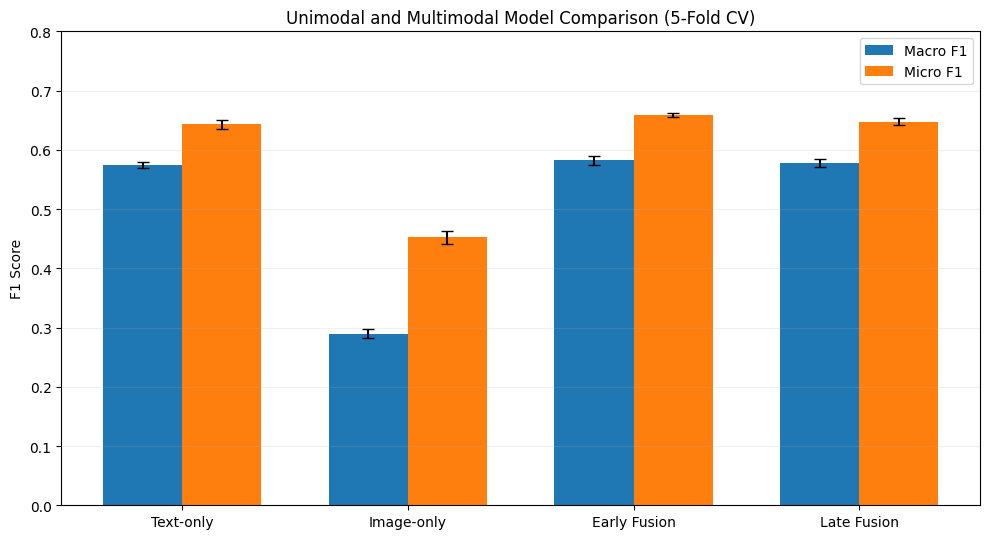


Section 10 model comparison: COMPLETED


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. Load results from all four approaches
# --------------------------------------------------

text_image_results = pd.read_csv(
    PROJECT_DIR / "results/threshold_tuning"
    / "threshold_tuning_results.csv"
)

early_results = pd.read_csv(
    PROJECT_DIR / "results/early_fusion"
    / "early_fusion_threshold_results.csv"
)

late_results = pd.read_csv(
    PROJECT_DIR / "results/late_fusion"
    / "late_fusion_tuned_cv_results.csv"
)

# Standardise metric names
unimodal_df = text_image_results[
    [
        "Model", "Fold",
        "Outer Macro F1 (Tuned)",
        "Outer Micro F1 (Tuned)",
        "Outer Precision (Tuned)",
        "Outer Recall (Tuned)"
    ]
].rename(columns={
    "Outer Macro F1 (Tuned)": "Macro F1",
    "Outer Micro F1 (Tuned)": "Micro F1",
    "Outer Precision (Tuned)": "Macro Precision",
    "Outer Recall (Tuned)": "Macro Recall"
})

early_df = early_results[
    [
        "Fold",
        "Tuned Macro F1",
        "Tuned Micro F1",
        "Tuned Macro Precision",
        "Tuned Macro Recall"
    ]
].rename(columns={
    "Tuned Macro F1": "Macro F1",
    "Tuned Micro F1": "Micro F1",
    "Tuned Macro Precision": "Macro Precision",
    "Tuned Macro Recall": "Macro Recall"
})

early_df["Model"] = "Early Fusion"

late_df = late_results[
    [
        "Fold",
        "Macro F1",
        "Micro F1",
        "Macro Precision",
        "Macro Recall"
    ]
].copy()

late_df["Model"] = "Late Fusion"

# Combine results
all_results = pd.concat(
    [unimodal_df, early_df, late_df],
    ignore_index=True
)

model_order = [
    "Text-only",
    "Image-only",
    "Early Fusion",
    "Late Fusion"
]

metrics = [
    "Macro F1",
    "Micro F1",
    "Macro Precision",
    "Macro Recall"
]

# Verify complete and matching fold coverage
for model_name in model_order:
    model_folds = sorted(
        all_results.loc[
            all_results["Model"] == model_name, "Fold"
        ].tolist()
    )

    assert model_folds == [1, 2, 3, 4, 5], (
        f"Unexpected folds for {model_name}"
    )

# --------------------------------------------------
# 2. Calculate model comparison statistics
# --------------------------------------------------

summary_rows = []

for model_name in model_order:
    subset = all_results[
        all_results["Model"] == model_name
    ]

    row = {"Model": model_name}

    for metric in metrics:
        row[f"{metric} Mean"] = subset[metric].mean()
        row[f"{metric} SD"] = subset[metric].std(ddof=1)

    summary_rows.append(row)

comparison_summary = pd.DataFrame(summary_rows)

print("===== Final Model Comparison =====")
print(comparison_summary.round(4).to_string(index=False))

# --------------------------------------------------
# 3. Calculate paired fold-level differences
# --------------------------------------------------

macro_pivot = all_results.pivot(
    index="Fold",
    columns="Model",
    values="Macro F1"
)

micro_pivot = all_results.pivot(
    index="Fold",
    columns="Model",
    values="Micro F1"
)

paired_differences = pd.DataFrame({
    "Early - Text (Macro F1)":
        macro_pivot["Early Fusion"]
        - macro_pivot["Text-only"],

    "Late - Text (Macro F1)":
        macro_pivot["Late Fusion"]
        - macro_pivot["Text-only"],

    "Early - Late (Macro F1)":
        macro_pivot["Early Fusion"]
        - macro_pivot["Late Fusion"],

    "Early - Late (Micro F1)":
        micro_pivot["Early Fusion"]
        - micro_pivot["Late Fusion"]
}).reset_index()

print("\n===== Paired Fold Differences =====")
print(paired_differences.round(4).to_string(index=False))

print("\n===== Mean Paired Differences =====")
print(
    paired_differences.drop(columns="Fold")
    .mean()
    .round(4)
    .to_string()
)

# --------------------------------------------------
# 4. Visualise Macro F1 and Micro F1
# --------------------------------------------------

x = np.arange(len(model_order))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.bar(
    x - width / 2,
    comparison_summary["Macro F1 Mean"],
    width,
    yerr=comparison_summary["Macro F1 SD"],
    capsize=4,
    label="Macro F1"
)

ax.bar(
    x + width / 2,
    comparison_summary["Micro F1 Mean"],
    width,
    yerr=comparison_summary["Micro F1 SD"],
    capsize=4,
    label="Micro F1"
)

ax.set_xticks(x)
ax.set_xticklabels(model_order)
ax.set_ylabel("F1 Score")
ax.set_ylim(0, 0.8)
ax.set_title(
    "Unimodal and Multimodal Model Comparison (5-Fold CV)"
)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

# --------------------------------------------------
# 5. Save tables and figure
# --------------------------------------------------

FINAL_COMPARISON_DIR = PROJECT_DIR / "results/comparison"
FINAL_COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

all_results.to_csv(
    FINAL_COMPARISON_DIR / "all_models_fold_results.csv",
    index=False
)

comparison_summary.to_csv(
    FINAL_COMPARISON_DIR / "final_model_comparison.csv",
    index=False
)

paired_differences.to_csv(
    FINAL_COMPARISON_DIR / "paired_fold_differences.csv",
    index=False
)

plt.savefig(
    FINAL_COMPARISON_DIR / "final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nSection 10 model comparison: COMPLETED")

## 11. Final Model Evaluation

### 11.1. Final Training and Calibration

The model architectures and training hyperparameters
are fixed based on the development cross-validation
experiments.

A group-aware split of the development set is used
for final model training and calibration.

Three classifiers are trained independently:
- Text-only
- Image-only
- Early Fusion

The same training and calibration records are used
for all three approaches. Feature scalers are fitted
exclusively on the final training records.

Early stopping and classification thresholds are
selected using the calibration set.

Late Fusion will combine the final unimodal
predictions, with weights selected on calibration data.

The independent holdout test set is not accessed
during this stage.

In [24]:

import copy
import random
import joblib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from torch.utils.data import DataLoader, TensorDataset

# --------------------------------------------------
# 11.1. Final Training and Calibration
# --------------------------------------------------

FINAL_DIR = PROJECT_DIR / "results" / "final_evaluation"
FINAL_DIR.mkdir(parents=True, exist_ok=True)

FINAL_SEED = SEED + 100

random.seed(FINAL_SEED)
np.random.seed(FINAL_SEED)
torch.manual_seed(FINAL_SEED)

# Create one shared group-aware calibration split
final_fit_idx, final_cal_idx = create_inner_split(
    dev_idx,
    seed=FINAL_SEED
)

# Verify sample and group isolation
assert len(np.intersect1d(final_fit_idx, final_cal_idx)) == 0

assert np.array_equal(
    np.sort(np.concatenate([final_fit_idx, final_cal_idx])),
    np.sort(dev_idx)
)

assert np.intersect1d(
    group_ids[final_fit_idx],
    group_ids[final_cal_idx]
).size == 0

assert np.intersect1d(
    group_ids[dev_idx],
    group_ids[test_idx]
).size == 0

print("Final development partition:")
print("Training records:", len(final_fit_idx))
print("Calibration records:", len(final_cal_idx))
print("Reserved test records:", len(test_idx))

print(
    "Minimum positive calibration examples:",
    int(y[final_cal_idx].sum(axis=0).min())
)

# Save the final split
np.savez_compressed(
    FINAL_DIR / "final_split_indices.npz",
    fit_idx=final_fit_idx,
    calibration_idx=final_cal_idx,
    test_idx=test_idx
)

# --------------------------------------------------
# 1. Fit scalers only on final training records
# --------------------------------------------------

final_text_scaler = StandardScaler().fit(
    np.asarray(X_text[final_fit_idx])
)

final_image_scaler = StandardScaler().fit(
    np.asarray(X_image[final_fit_idx])
)

joblib.dump(
    final_text_scaler,
    FINAL_DIR / "final_text_scaler.joblib"
)

joblib.dump(
    final_image_scaler,
    FINAL_DIR / "final_image_scaler.joblib"
)

def prepare_final_features(indices, model_name):

    text_features = final_text_scaler.transform(
        np.asarray(X_text[indices])
    ).astype(np.float32)

    if model_name == "text_only":
        return text_features

    image_features = final_image_scaler.transform(
        np.asarray(X_image[indices])
    ).astype(np.float32)

    if model_name == "image_only":
        return image_features

    if model_name == "early_fusion":
        return np.concatenate(
            [text_features, image_features],
            axis=1
        )

    raise ValueError(f"Unknown model: {model_name}")


# --------------------------------------------------
# 2. Final model training function
# --------------------------------------------------

def train_final_classifier(model_name):

    random.seed(FINAL_SEED)
    np.random.seed(FINAL_SEED)
    torch.manual_seed(FINAL_SEED)

    X_fit = prepare_final_features(
        final_fit_idx, model_name
    )

    X_cal = prepare_final_features(
        final_cal_idx, model_name
    )

    assert np.isfinite(X_fit).all()
    assert np.isfinite(X_cal).all()

    train_loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_fit),
            torch.from_numpy(y[final_fit_idx].copy())
        ),
        batch_size=BATCH_SIZE,
        shuffle=True
    )

    model = UnimodalMLP(
        input_dim=X_fit.shape[1],
        hidden_dim=HIDDEN_DIM,
        num_labels=NUM_LABELS,
        dropout=DROPOUT
    ).to(device)

    criterion = nn.BCEWithLogitsLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    x_cal = torch.from_numpy(X_cal).to(device)
    y_cal = torch.from_numpy(
        y[final_cal_idx].copy()
    ).to(device)

    best_loss = float("inf")
    best_epoch = 0
    best_state = None
    patience_counter = 0
    history = []

    print(f"\n===== Final {model_name} Training =====")

    for epoch in range(1, MAX_EPOCHS + 1):

        model.train()
        total_loss = 0.0

        for batch_x, batch_y in train_loader:

            batch_x = batch_x.to(device)
            batch_y = batch_y.to(device)

            optimizer.zero_grad(set_to_none=True)

            loss = criterion(model(batch_x), batch_y)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(batch_x)

        train_loss = total_loss / len(final_fit_idx)

        model.eval()

        with torch.inference_mode():
            cal_loss = criterion(
                model(x_cal), y_cal
            ).item()

        history.append({
            "Epoch": epoch,
            "Train Loss": train_loss,
            "Calibration Loss": cal_loss
        })

        print(
            f"Epoch {epoch:02d} | "
            f"Train: {train_loss:.4f} | "
            f"Calibration: {cal_loss:.4f}"
        )

        if cal_loss < best_loss - 1e-4:

            best_loss = cal_loss
            best_epoch = epoch
            best_state = copy.deepcopy(
                model.state_dict()
            )
            patience_counter = 0

        else:
            patience_counter += 1

            if patience_counter >= PATIENCE:
                print("Early stopping triggered.")
                break

    # Restore selected checkpoint
    assert best_state is not None

    model.load_state_dict(best_state)
    model.eval()

    # Predict calibration probabilities
    with torch.inference_mode():
        cal_probs = torch.sigmoid(
            model(x_cal)
        ).cpu().numpy()

    threshold_grid = np.round(
        np.arange(0.05, 0.501, 0.025), 3
    )

    cal_scores = [
        f1_score(
            y[final_cal_idx],
            cal_probs >= threshold,
            average="macro",
            zero_division=0
        )
        for threshold in threshold_grid
    ]

    best_position = int(np.argmax(cal_scores))
    selected_threshold = float(
        threshold_grid[best_position]
    )

    # Save trained classifier
    torch.save(
        best_state,
        FINAL_DIR / f"{model_name}_final_model.pt"
    )

    # Save training history
    pd.DataFrame(history).to_csv(
        FINAL_DIR / f"{model_name}_training_history.csv",
        index=False
    )

    # Save calibration probabilities
    np.savez_compressed(
        FINAL_DIR / f"{model_name}_calibration_predictions.npz",
        indices=final_cal_idx,
        y_true=y[final_cal_idx],
        y_prob=cal_probs,
        selected_threshold=selected_threshold
    )

    result = {
        "Model": model_name,
        "Input Dimensions": X_fit.shape[1],
        "Best Epoch": best_epoch,
        "Best Calibration Loss": best_loss,
        "Selected Threshold": selected_threshold,
        "Calibration Macro F1": max(cal_scores)
    }

    print("\nFinal training result:")

    for key, value in result.items():
        print(f"{key}: {value}")

    print(f"\nFinal {model_name}: COMPLETED")

    return result


# --------------------------------------------------
# 3. Train all three final classifiers
# --------------------------------------------------

final_results = []

for model_name in [
    "text_only",
    "image_only",
    "early_fusion"
]:
    result = train_final_classifier(model_name)
    final_results.append(result)

final_training_df = pd.DataFrame(final_results)

final_training_df.to_csv(
    FINAL_DIR / "final_training_summary.csv",
    index=False
)

print("\n===== Final Training Summary =====")
print(final_training_df.round(4).to_string(index=False))

print("\nFinal training and calibration: COMPLETED")
print("Independent test predictions have NOT been generated.")


Final development partition:
Training records: 16359
Calibration records: 1817
Reserved test records: 7783
Minimum positive calibration examples: 26

===== Final text_only Training =====
Epoch 01 | Train: 0.2774 | Calibration: 0.1902
Epoch 02 | Train: 0.1873 | Calibration: 0.1823
Epoch 03 | Train: 0.1782 | Calibration: 0.1792
Epoch 04 | Train: 0.1731 | Calibration: 0.1776
Epoch 05 | Train: 0.1685 | Calibration: 0.1769
Epoch 06 | Train: 0.1662 | Calibration: 0.1765
Epoch 07 | Train: 0.1635 | Calibration: 0.1769
Epoch 08 | Train: 0.1609 | Calibration: 0.1771
Epoch 09 | Train: 0.1590 | Calibration: 0.1764
Epoch 10 | Train: 0.1567 | Calibration: 0.1772
Epoch 11 | Train: 0.1549 | Calibration: 0.1771
Epoch 12 | Train: 0.1534 | Calibration: 0.1774
Epoch 13 | Train: 0.1513 | Calibration: 0.1789
Early stopping triggered.

Final training result:
Model: text_only
Input Dimensions: 768
Best Epoch: 9
Best Calibration Loss: 0.17640544474124908
Selected Threshold: 0.175
Calibration Macro F1: 0.561813

#### 11.1.2. Final Late Fusion Calibration

The final text-only and image-only classifiers are
combined through weighted probability averaging.

The text weight and global decision threshold are
selected by maximising Macro F1 on the held-out
development calibration subset.

The search grid is identical to the late fusion
cross-validation experiment.

All parameters are saved before independent test
evaluation. No test labels or predictions are used
for parameter selection.

In [25]:
import numpy as np
import pandas as pd

from sklearn.metrics import f1_score

# --------------------------------------------------
# 1. Load final calibration predictions
# --------------------------------------------------

FINAL_DIR = PROJECT_DIR / "results" / "final_evaluation"

def load_final_calibration(model_name):

    path = (
        FINAL_DIR /
        f"{model_name}_calibration_predictions.npz"
    )

    with np.load(path) as saved:
        indices = saved["indices"].copy()
        labels = saved["y_true"].copy()
        probabilities = saved["y_prob"].copy()
        threshold = float(
            saved["selected_threshold"].item()
        )

    return indices, labels, probabilities, threshold


text_idx, text_true, text_probs, text_threshold = (
    load_final_calibration("text_only")
)

image_idx, image_true, image_probs, image_threshold = (
    load_final_calibration("image_only")
)

early_idx, early_true, early_probs, early_threshold = (
    load_final_calibration("early_fusion")
)

# Verify identical calibration samples and labels
assert np.array_equal(text_idx, image_idx)
assert np.array_equal(text_idx, early_idx)

assert np.array_equal(text_true, image_true)
assert np.array_equal(text_true, early_true)

assert np.array_equal(text_true, y[text_idx])

# Verify the saved development calibration partition
with np.load(
    FINAL_DIR / "final_split_indices.npz"
) as saved:
    expected_cal_idx = saved["calibration_idx"].copy()

assert np.array_equal(text_idx, expected_cal_idx)

assert np.isfinite(text_probs).all()
assert np.isfinite(image_probs).all()
assert np.isfinite(early_probs).all()

print("Calibration records:", len(text_idx))
print("All model predictions aligned: PASSED")


# --------------------------------------------------
# 2. Search Late Fusion weight and threshold
# --------------------------------------------------

WEIGHT_GRID = np.round(
    np.linspace(0.0, 1.0, 11), 2
)

THRESHOLD_GRID = np.round(
    np.arange(0.05, 0.501, 0.025), 3
)

search_results = []

best_score = -np.inf
best_weight = None
best_threshold = None
best_probs = None

for weight in WEIGHT_GRID:

    fused_probs = (
        weight * text_probs
        + (1.0 - weight) * image_probs
    )

    for threshold in THRESHOLD_GRID:

        score = f1_score(
            text_true,
            fused_probs >= threshold,
            average="macro",
            zero_division=0
        )

        search_results.append({
            "Text Weight": float(weight),
            "Image Weight": float(1.0 - weight),
            "Threshold": float(threshold),
            "Calibration Macro F1": float(score)
        })

        if score > best_score + 1e-12:
            best_score = float(score)
            best_weight = float(weight)
            best_threshold = float(threshold)
            best_probs = fused_probs.copy()


# --------------------------------------------------
# 3. Evaluate all four models on calibration data
# --------------------------------------------------

model_predictions = {
    "Text-only": (text_probs, text_threshold),
    "Image-only": (image_probs, image_threshold),
    "Early Fusion": (early_probs, early_threshold),
    "Late Fusion": (best_probs, best_threshold)
}

comparison_rows = []

for model_name, (probs, threshold) in model_predictions.items():

    metrics = calculate_metrics(
        text_true,
        probs,
        threshold=threshold
    )

    comparison_rows.append({
        "Model": model_name,
        "Threshold": threshold,
        **metrics
    })

calibration_comparison = pd.DataFrame(comparison_rows)

print("\n===== Final Late Fusion Calibration =====")

print("Selected text weight:", round(best_weight, 3))
print(
    "Selected image weight:",
    round(1.0 - best_weight, 3)
)
print("Selected threshold:", round(best_threshold, 3))
print("Calibration Macro F1:", round(best_score, 4))

print("\n===== Final Calibration Model Comparison =====")
print(
    calibration_comparison
    .round(4)
    .to_string(index=False)
)


# --------------------------------------------------
# 4. Save selected parameters and predictions
# --------------------------------------------------

late_config = pd.DataFrame([{
    "Text Weight": best_weight,
    "Image Weight": 1.0 - best_weight,
    "Selected Threshold": best_threshold,
    "Calibration Macro F1": best_score
}])

late_config.to_csv(
    FINAL_DIR / "late_fusion_final_config.csv",
    index=False
)

pd.DataFrame(search_results).to_csv(
    FINAL_DIR / "late_fusion_calibration_search.csv",
    index=False
)

calibration_comparison.to_csv(
    FINAL_DIR / "final_calibration_comparison.csv",
    index=False
)

np.savez_compressed(
    FINAL_DIR / "late_fusion_calibration_predictions.npz",
    indices=text_idx,
    y_true=text_true,
    y_prob=best_probs,
    text_weight=best_weight,
    selected_threshold=best_threshold
)

print("\nFinal Late Fusion calibration: COMPLETED")
print("All parameters saved.")
print("Independent test set remains untouched.")

Calibration records: 1817
All model predictions aligned: PASSED

===== Final Late Fusion Calibration =====
Selected text weight: 0.8
Selected image weight: 0.2
Selected threshold: 0.2
Calibration Macro F1: 0.563

===== Final Calibration Model Comparison =====
       Model  Threshold  Macro F1  Micro F1  Macro Precision  Macro Recall
   Text-only      0.175    0.5618    0.6289           0.4906        0.6710
  Image-only      0.175    0.2955    0.4747           0.2962        0.3765
Early Fusion      0.225    0.5687    0.6508           0.5455        0.6132
 Late Fusion      0.200    0.5630    0.6422           0.5219        0.6335

Final Late Fusion calibration: COMPLETED
All parameters saved.
Independent test set remains untouched.


### 11.2. Independent Holdout Test Evaluation

The four final classification approaches are evaluated
on the independent holdout test set of 7,783 movies.

Model architectures, training hyperparameters, decision
thresholds and late-fusion weights were determined using
development data only.

The saved final checkpoints and training-fitted scalers
are restored for inference.

Macro F1, Micro F1, Macro Precision and Macro Recall
are reported for all four approaches.

The previously selected Early Fusion model remains the
primary model, regardless of the test-set ranking.

All test predictions and metrics are saved to support
subsequent per-genre evaluation and error analysis.

In [26]:

import numpy as np
import pandas as pd
import torch
import joblib

# --------------------------------------------------
# 11.2. Independent Holdout Test Evaluation
# --------------------------------------------------

FINAL_DIR = PROJECT_DIR / "results" / "final_evaluation"

# --------------------------------------------------
# 1. Restore final dataset split
# --------------------------------------------------

with np.load(FINAL_DIR / "final_split_indices.npz") as saved:
    saved_fit_idx = saved["fit_idx"].copy()
    saved_cal_idx = saved["calibration_idx"].copy()
    saved_test_idx = saved["test_idx"].copy()

# Verify the original holdout test set
assert np.array_equal(
    np.sort(saved_test_idx),
    np.sort(test_idx)
)

assert len(np.unique(test_idx)) == len(test_idx)

assert np.intersect1d(
    group_ids[dev_idx],
    group_ids[test_idx]
).size == 0

assert np.intersect1d(saved_fit_idx, test_idx).size == 0
assert np.intersect1d(saved_cal_idx, test_idx).size == 0

y_test = y[test_idx]

print("Independent Test Set:")
print("Test records:", len(test_idx))
print("Genre labels:", y_test.shape[1])
print("Group isolation: PASSED")

# --------------------------------------------------
# 2. Restore saved training scalers
# --------------------------------------------------

text_scaler = joblib.load(
    FINAL_DIR / "final_text_scaler.joblib"
)

image_scaler = joblib.load(
    FINAL_DIR / "final_image_scaler.joblib"
)

# Verify scalers were fitted on final training only
assert int(text_scaler.n_samples_seen_) == len(saved_fit_idx)
assert int(image_scaler.n_samples_seen_) == len(saved_fit_idx)

# Prepare the held-out test features
X_text_test = text_scaler.transform(
    np.asarray(X_text[test_idx])
).astype(np.float32)

X_image_test = image_scaler.transform(
    np.asarray(X_image[test_idx])
).astype(np.float32)

X_fusion_test = np.concatenate(
    [X_text_test, X_image_test],
    axis=1
)

assert X_text_test.shape == (len(test_idx), 768)
assert X_image_test.shape == (len(test_idx), 768)
assert X_fusion_test.shape == (len(test_idx), 1536)

assert np.isfinite(X_text_test).all()
assert np.isfinite(X_image_test).all()
assert np.isfinite(X_fusion_test).all()

print("\nTest feature preparation: PASSED")

# --------------------------------------------------
# 3. Restore final models and predict probabilities
# --------------------------------------------------

def predict_final_test_model(model_name, features):

    # Restore trained model
    model = UnimodalMLP(
        input_dim=features.shape[1],
        hidden_dim=HIDDEN_DIM,
        num_labels=NUM_LABELS,
        dropout=DROPOUT
    ).to(device)

    state = torch.load(
        FINAL_DIR / f"{model_name}_final_model.pt",
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(state)
    model.eval()

    # Predict in batches
    predictions = []

    for start in range(0, len(features), BATCH_SIZE):

        batch = torch.from_numpy(
            features[start:start + BATCH_SIZE]
        ).to(device)

        with torch.inference_mode():
            probs = torch.sigmoid(
                model(batch)
            ).cpu().numpy()

        predictions.append(probs)

    probabilities = np.concatenate(
        predictions,
        axis=0
    )

    assert probabilities.shape == (
        len(test_idx), NUM_LABELS
    )

    assert np.isfinite(probabilities).all()
    assert np.all(
        (probabilities >= 0) & (probabilities <= 1)
    )

    return probabilities


# Predict three trained classifiers
test_probs = {}

test_features = {
    "text_only": X_text_test,
    "image_only": X_image_test,
    "early_fusion": X_fusion_test
}

for model_name, features in test_features.items():

    test_probs[model_name] = predict_final_test_model(
        model_name, features
    )

    print(f"{model_name}: predictions generated")

# --------------------------------------------------
# 4. Load previously selected thresholds
# --------------------------------------------------

final_training_df = pd.read_csv(
    FINAL_DIR / "final_training_summary.csv"
)

model_thresholds = {
    row["Model"]: float(row["Selected Threshold"])
    for _, row in final_training_df.iterrows()
}

assert set(test_features).issubset(model_thresholds)

# Restore final Late Fusion configuration
late_config = pd.read_csv(
    FINAL_DIR / "late_fusion_final_config.csv"
).iloc[0]

text_weight = float(late_config["Text Weight"])
image_weight = float(late_config["Image Weight"])

late_threshold = float(
    late_config["Selected Threshold"]
)

assert np.isclose(text_weight + image_weight, 1.0)

# Late Fusion: weighted probability averaging
test_probs["late_fusion"] = (
    text_weight * test_probs["text_only"]
    + image_weight * test_probs["image_only"]
)

model_thresholds["late_fusion"] = late_threshold

print("\nSaved Late Fusion configuration:")
print("Text weight:", text_weight)
print("Image weight:", image_weight)
print("Threshold:", late_threshold)

# --------------------------------------------------
# 5. Evaluate all four models using fixed thresholds
# --------------------------------------------------

model_order = [
    "text_only",
    "image_only",
    "early_fusion",
    "late_fusion"
]

model_names = {
    "text_only": "Text-only",
    "image_only": "Image-only",
    "early_fusion": "Early Fusion",
    "late_fusion": "Late Fusion"
}

test_results = []

for model_name in model_order:

    threshold = model_thresholds[model_name]
    probabilities = test_probs[model_name]

    metrics = calculate_metrics(
        y_test,
        probabilities,
        threshold=threshold
    )

    test_results.append({
        "Model": model_names[model_name],
        "Threshold": threshold,
        **metrics
    })

    # Save test probabilities for error analysis
    np.savez_compressed(
        FINAL_DIR / f"{model_name}_test_predictions.npz",
        indices=test_idx,
        y_true=y_test,
        y_prob=probabilities,
        selected_threshold=threshold
    )

test_results_df = pd.DataFrame(test_results)

# --------------------------------------------------
# 6. Report held-out test metrics
# --------------------------------------------------

print("\n===== Independent Holdout Test Results =====")
print(
    test_results_df
    .round(4)
    .to_string(index=False)
)

# Compare fusion models against text-only
text_row = test_results_df[
    test_results_df["Model"] == "Text-only"
].iloc[0]

fusion_rows = test_results_df[
    test_results_df["Model"].isin(
        ["Early Fusion", "Late Fusion"]
    )
].copy()

fusion_rows["Macro F1 Difference vs Text"] = (
    fusion_rows["Macro F1"] - text_row["Macro F1"]
)

fusion_rows["Micro F1 Difference vs Text"] = (
    fusion_rows["Micro F1"] - text_row["Micro F1"]
)

print("\n===== Fusion vs Text-only =====")
print(
    fusion_rows[
        [
            "Model",
            "Macro F1 Difference vs Text",
            "Micro F1 Difference vs Text"
        ]
    ].round(4).to_string(index=False)
)

# --------------------------------------------------
# 7. Save final test results
# --------------------------------------------------

test_results_df.to_csv(
    FINAL_DIR / "independent_test_results.csv",
    index=False
)

fusion_rows.to_csv(
    FINAL_DIR / "test_fusion_vs_text.csv",
    index=False
)

print("\nIndependent test evaluation: COMPLETED")
print("All four models evaluated using fixed parameters.")
print("Test results and predictions saved successfully.")


Independent Test Set:
Test records: 7783
Genre labels: 23
Group isolation: PASSED

Test feature preparation: PASSED
text_only: predictions generated
image_only: predictions generated
early_fusion: predictions generated

Saved Late Fusion configuration:
Text weight: 0.8
Image weight: 0.1999999999999999
Threshold: 0.2

===== Independent Holdout Test Results =====
       Model  Threshold  Macro F1  Micro F1  Macro Precision  Macro Recall
   Text-only      0.175    0.5701    0.6240           0.4968        0.6811
  Image-only      0.175    0.2858    0.4688           0.2959        0.3674
Early Fusion      0.225    0.5788    0.6473           0.5641        0.6229
 Late Fusion      0.200    0.5814    0.6376           0.5430        0.6494

===== Fusion vs Text-only =====
       Model  Macro F1 Difference vs Text  Micro F1 Difference vs Text
Early Fusion                       0.0087                       0.0233
 Late Fusion                       0.0113                       0.0136

Independent te

### 11.3. Per-Genre Performance Analysis

Per-genre precision, recall, F1 and average precision
are calculated for the four final classifiers.

The saved test probabilities and pre-selected thresholds
are used without modification.

Genre-level comparisons identify classes that benefit
from multimodal fusion and classes that remain difficult
to predict.

Class support is reported to investigate the potential
effects of label imbalance.

These results are used for diagnostic interpretation
only, not for further model optimisation.

In [27]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_recall_fscore_support,
    average_precision_score
)

FINAL_DIR = PROJECT_DIR / "results" / "final_evaluation"

models = {
    "text_only": "Text-only",
    "image_only": "Image-only",
    "early_fusion": "Early Fusion",
    "late_fusion": "Late Fusion"
}

# Temporary labels until the official genre mapping is verified
genre_names = [
    f"Genre {i}" for i in range(y.shape[1])
]

per_genre_rows = []

# Calculate test metrics separately for each genre
for model_id, model_name in models.items():

    with np.load(
        FINAL_DIR / f"{model_id}_test_predictions.npz"
    ) as saved:

        indices = saved["indices"].copy()
        y_true = saved["y_true"].copy()
        y_prob = saved["y_prob"].copy()
        threshold = float(
            saved["selected_threshold"].item()
        )

    # Verify test alignment
    assert np.array_equal(indices, test_idx)
    assert np.array_equal(y_true, y[test_idx])

    # Apply the previously selected threshold
    y_pred = (y_prob >= threshold).astype(int)

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average=None,
            zero_division=0
        )
    )

    average_precision = average_precision_score(
        y_true,
        y_prob,
        average=None
    )

    for genre_idx in range(y.shape[1]):

        per_genre_rows.append({
            "Model": model_name,
            "Genre Index": genre_idx,
            "Genre": genre_names[genre_idx],
            "Support": int(support[genre_idx]),
            "Precision": precision[genre_idx],
            "Recall": recall[genre_idx],
            "F1": f1[genre_idx],
            "Average Precision": average_precision[genre_idx]
        })

# Create per-genre results table
per_genre_df = pd.DataFrame(per_genre_rows)

# Compare genre-level F1 across models
genre_comparison = per_genre_df.pivot(
    index=["Genre Index", "Genre", "Support"],
    columns="Model",
    values="F1"
).reset_index()

genre_comparison["Early - Text"] = (
    genre_comparison["Early Fusion"]
    - genre_comparison["Text-only"]
)

genre_comparison["Late - Text"] = (
    genre_comparison["Late Fusion"]
    - genre_comparison["Text-only"]
)

# Display the most challenging genres
print("===== Lowest Early Fusion Genre F1 =====")

print(
    genre_comparison.sort_values(
        "Early Fusion"
    ).head(10).round(4).to_string(index=False)
)

# Display genres benefiting most from Early Fusion
print("\n===== Largest Early Fusion Gains =====")

print(
    genre_comparison.sort_values(
        "Early - Text",
        ascending=False
    ).head(10).round(4).to_string(index=False)
)

# Display genres benefiting most from Late Fusion
print("\n===== Largest Late Fusion Gains =====")

print(
    genre_comparison.sort_values(
        "Late - Text",
        ascending=False
    ).head(10).round(4).to_string(index=False)
)

# Count per-genre improvements
early_improved = int(
    (genre_comparison["Early - Text"] > 0).sum()
)

late_improved = int(
    (genre_comparison["Late - Text"] > 0).sum()
)

print("\n===== Genre-Level Improvement Summary =====")
print(f"Early Fusion improved: {early_improved}/23 genres")
print(f"Late Fusion improved: {late_improved}/23 genres")

# Save diagnostic results
per_genre_df.to_csv(
    FINAL_DIR / "per_genre_test_metrics.csv",
    index=False
)

genre_comparison.to_csv(
    FINAL_DIR / "per_genre_f1_comparison.csv",
    index=False
)

print("\nPer-genre test analysis: COMPLETED")
print("Diagnostic tables saved successfully.")

===== Lowest Early Fusion Genre F1 =====
 Genre Index    Genre  Support  Early Fusion  Image-only  Late Fusion  Text-only  Early - Text  Late - Text
          22 Genre 22       95        0.2459      0.0000       0.2254     0.2458        0.0001      -0.0205
          18 Genre 18      256        0.3584      0.2043       0.4208     0.3979       -0.0395       0.0229
          21 Genre 21      140        0.3714      0.0268       0.3707     0.4130       -0.0416      -0.0424
          13 Genre 13      416        0.4230      0.0284       0.5012     0.4861       -0.0632       0.0151
          15 Genre 15      362        0.4233      0.0559       0.4603     0.4484       -0.0251       0.0119
          11 Genre 11      568        0.4776      0.2888       0.4910     0.4763        0.0012       0.0147
           9  Genre 9      641        0.4830      0.2034       0.4735     0.4688        0.0142       0.0047
           2  Genre 2     1570        0.5391      0.4096       0.5448     0.5312        0.0078 

### 11.4. Error Analysis and Model Limitations

#### 11.4.1. Quantitative Classification Error Analysis

The saved independent test predictions are used to
analyse true positives, false positives and false
negatives for each classification approach.

Exact-match accuracy and mean label errors per movie
are also calculated to examine multi-label performance.

Early and Late Fusion are compared against Text-only
to determine how many prediction errors are corrected
or introduced by multimodal integration.

All thresholds remain fixed at their previously
selected calibration values. This analysis is
diagnostic and does not involve model optimisation.

In [28]:

import numpy as np
import pandas as pd

FINAL_DIR = PROJECT_DIR / "results" / "final_evaluation"

model_names = {
    "text_only": "Text-only",
    "image_only": "Image-only",
    "early_fusion": "Early Fusion",
    "late_fusion": "Late Fusion"
}

# Ground-truth test labels
y_test_bool = y[test_idx].astype(bool)

predictions = {}
movie_error_counts = {}
error_summary_rows = []

# --------------------------------------------------
# 1. Load test predictions and count errors
# --------------------------------------------------

for model_id, model_name in model_names.items():

    prediction_path = (
        FINAL_DIR / f"{model_id}_test_predictions.npz"
    )

    with np.load(prediction_path) as saved:
        indices = saved["indices"].copy()
        labels = saved["y_true"].copy()
        probabilities = saved["y_prob"].copy()
        threshold = float(
            saved["selected_threshold"].item()
        )

    # Verify alignment with the independent test set
    assert np.array_equal(indices, test_idx)
    assert np.array_equal(labels, y[test_idx])
    assert probabilities.shape == y_test_bool.shape
    assert np.isfinite(probabilities).all()

    # Apply the original calibration-selected threshold
    y_pred = probabilities >= threshold

    predictions[model_id] = y_pred

    # Compute multi-label classification errors
    tp = int(np.sum(y_pred & y_test_bool))
    fp = int(np.sum(y_pred & ~y_test_bool))
    fn = int(np.sum(~y_pred & y_test_bool))

    errors_per_movie = np.sum(
        y_pred != y_test_bool,
        axis=1
    )

    movie_error_counts[model_id] = errors_per_movie

    exact_match_count = int(
        np.sum(errors_per_movie == 0)
    )

    error_summary_rows.append({
        "Model": model_name,
        "Threshold": threshold,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Total Label Errors": fp + fn,
        "Mean Errors per Movie": errors_per_movie.mean(),
        "Exact Match Accuracy": (
            exact_match_count / len(test_idx)
        )
    })

error_summary_df = pd.DataFrame(error_summary_rows)

print("===== Test Classification Error Summary =====\n")
print(error_summary_df.round(4).to_string(index=False))


# --------------------------------------------------
# 2. Compare fusion methods against Text-only
# --------------------------------------------------

text_errors = movie_error_counts["text_only"]

# Identify all label-level errors made by Text-only
text_wrong = (
    predictions["text_only"] != y_test_bool
)

comparison_rows = []

for model_id in ["early_fusion", "late_fusion"]:

    fusion_errors = movie_error_counts[model_id]

    fusion_wrong = (
        predictions[model_id] != y_test_bool
    )

    # Label errors corrected or newly introduced
    corrected_labels = int(
        np.sum(text_wrong & ~fusion_wrong)
    )

    introduced_errors = int(
        np.sum(~text_wrong & fusion_wrong)
    )

    comparison_rows.append({
        "Model": model_names[model_id],
        "Improved Movies": int(
            np.sum(fusion_errors < text_errors)
        ),
        "Unchanged Error Count": int(
            np.sum(fusion_errors == text_errors)
        ),
        "Worsened Movies": int(
            np.sum(fusion_errors > text_errors)
        ),
        "Corrected Label Errors": corrected_labels,
        "Introduced Label Errors": introduced_errors,
        "Net Errors Reduced": (
            corrected_labels - introduced_errors
        )
    })

movie_comparison_df = pd.DataFrame(comparison_rows)

# Verify total movie counts
for _, row in movie_comparison_df.iterrows():
    assert (
        row["Improved Movies"]
        + row["Unchanged Error Count"]
        + row["Worsened Movies"]
        == len(test_idx)
    )

print("\n===== Fusion vs Text-only: Error Changes =====\n")
print(movie_comparison_df.to_string(index=False))


# --------------------------------------------------
# 3. Save results for the report
# --------------------------------------------------

error_summary_df.to_csv(
    FINAL_DIR / "test_error_summary.csv",
    index=False
)

movie_comparison_df.to_csv(
    FINAL_DIR / "movie_level_error_comparison.csv",
    index=False
)

np.savez_compressed(
    FINAL_DIR / "movie_error_counts.npz",
    indices=test_idx,
    text_only=movie_error_counts["text_only"],
    image_only=movie_error_counts["image_only"],
    early_fusion=movie_error_counts["early_fusion"],
    late_fusion=movie_error_counts["late_fusion"]
)

print("\nQuantitative error analysis: COMPLETED")
print("Results saved successfully.")


===== Test Classification Error Summary =====

       Model  Threshold    TP    FP   FN  Total Label Errors  Mean Errors per Movie  Exact Match Accuracy
   Text-only      0.175 15348 14507 3991               18498                 2.3767                0.0794
  Image-only      0.175 12056 20036 7283               27319                 3.5101                0.0245
Early Fusion      0.225 14469 10901 4870               15771                 2.0263                0.1190
 Late Fusion      0.200 15121 12970 4218               17188                 2.2084                0.0914

===== Fusion vs Text-only: Error Changes =====

       Model  Improved Movies  Unchanged Error Count  Worsened Movies  Corrected Label Errors  Introduced Label Errors  Net Errors Reduced
Early Fusion             3107                   3274             1402                    5786                     3059                2727
 Late Fusion             1778                   5268              737                    2371   

#### 11.4.2. Qualitative Analysis of Prediction Errors

Representative test examples are selected based on the
difference in label errors between Early Fusion and
Text-only.

The analysis identifies the movies with the greatest
error reduction and the greatest performance degradation.

For each example, the plot summary, true genre labels,
predicted labels, false positives and false negatives
are examined.

The examples are used to interpret the advantages and
limitations of multimodal fusion, without modifying
the trained models or selected thresholds.

In [30]:
# ============================================================
# 11.4.2. Qualitative Error Analysis
# ============================================================

import numpy as np
import pandas as pd

FINAL_DIR = PROJECT_DIR / "results" / "final_evaluation"

# ------------------------------------------------------------
# 1. Retrieve predictions and ground-truth labels
# ------------------------------------------------------------

y_true = y[test_idx].astype(bool)

text_pred = predictions["text_only"]
early_pred = predictions["early_fusion"]

text_errors = movie_error_counts["text_only"]
early_errors = movie_error_counts["early_fusion"]

# Verify data alignment
assert text_pred.shape == y_true.shape
assert early_pred.shape == y_true.shape
assert len(text_errors) == len(test_idx)
assert len(early_errors) == len(test_idx)

# Positive value: Early Fusion makes fewer errors
# Negative value: Early Fusion makes more errors
error_reduction = text_errors - early_errors

# ------------------------------------------------------------
# 2. Select the most improved and worsened movies
# ------------------------------------------------------------

improved_idx = np.where(error_reduction > 0)[0]
worsened_idx = np.where(error_reduction < 0)[0]

# Select up to 3 cases with the largest improvement
best_cases = improved_idx[
    np.argsort(-error_reduction[improved_idx])
][:3]

# Select up to 3 cases with the largest degradation
worst_cases = worsened_idx[
    np.argsort(error_reduction[worsened_idx])
][:3]

print("Selected improved cases:", len(best_cases))
print("Selected worsened cases:", len(worst_cases))


# ------------------------------------------------------------
# 3. Helper function to format genre labels
# ------------------------------------------------------------

def format_genres(label_vector):
    """Convert a binary genre vector into readable indices."""

    indices = np.flatnonzero(label_vector)

    if len(indices) == 0:
        return "None"

    return ", ".join(
        f"Genre {i}" for i in indices
    )


# ------------------------------------------------------------
# 4. Inspect a single movie
# ------------------------------------------------------------

def inspect_movie(position, case_type):

    record_idx = int(test_idx[position])

    true_labels = y_true[position]
    text_labels = text_pred[position]
    early_labels = early_pred[position]

    # Identify false positives and false negatives
    text_fp = text_labels & ~true_labels
    text_fn = ~text_labels & true_labels

    early_fp = early_labels & ~true_labels
    early_fn = ~early_labels & true_labels

    # Errors corrected by Early Fusion
    corrected = (
        (text_labels != true_labels)
        & (early_labels == true_labels)
    )

    # New errors introduced by Early Fusion
    introduced = (
        (text_labels == true_labels)
        & (early_labels != true_labels)
    )

    # Retrieve the original plot summary
    plot_summary = str(records[record_idx, 2])
    plot_excerpt = plot_summary[:500].replace("\n", " ")

    # Print case details
    print("\n" + "=" * 65)
    print(f"Case: {case_type}")
    print(f"Record index: {record_idx}")
    print(f"Error reduction: {int(error_reduction[position]):+d}")

    print("\nPlot summary:")
    print(plot_excerpt)

    print("\nGround-truth genres:")
    print(format_genres(true_labels))

    print("\nText-only predictions:")
    print(format_genres(text_labels))
    print("False positives:", format_genres(text_fp))
    print("False negatives:", format_genres(text_fn))
    print("Total errors:", int(text_errors[position]))

    print("\nEarly Fusion predictions:")
    print(format_genres(early_labels))
    print("False positives:", format_genres(early_fp))
    print("False negatives:", format_genres(early_fn))
    print("Total errors:", int(early_errors[position]))

    print("\nChanges introduced by Early Fusion:")
    print("Corrected labels:", format_genres(corrected))
    print("New label errors:", format_genres(introduced))

    # Return results for saving
    return {
        "Case Type": case_type,
        "Record Index": record_idx,
        "Error Reduction": int(error_reduction[position]),
        "True Genres": format_genres(true_labels),
        "Text Predictions": format_genres(text_labels),
        "Early Predictions": format_genres(early_labels),
        "Corrected Labels": format_genres(corrected),
        "Introduced Errors": format_genres(introduced),
        "Text Error Count": int(text_errors[position]),
        "Early Error Count": int(early_errors[position]),
        "Plot Excerpt": plot_excerpt
    }


# ------------------------------------------------------------
# 5. Analyse selected cases
# ------------------------------------------------------------

case_results = []

print("\n===== MOST IMPROVED MOVIES =====")

for position in best_cases:
    result = inspect_movie(position, "Improved")
    case_results.append(result)

print("\n===== MOST WORSENED MOVIES =====")

for position in worst_cases:
    result = inspect_movie(position, "Worsened")
    case_results.append(result)


# ------------------------------------------------------------
# 6. Save results
# ------------------------------------------------------------

case_df = pd.DataFrame(case_results)

case_df.to_csv(
    FINAL_DIR / "qualitative_error_cases.csv",
    index=False
)

print("\n===== Qualitative Analysis Summary =====")
print(
    case_df[
        [
            "Case Type",
            "Record Index",
            "Error Reduction",
            "Text Error Count",
            "Early Error Count"
        ]
    ].to_string(index=False)
)

print("\nQualitative error analysis: COMPLETED")
print("Results saved successfully.")

Selected improved cases: 3
Selected worsened cases: 3

===== MOST IMPROVED MOVIES =====

Case: Improved
Record index: 5563
Error reduction: +7

Plot summary:
everyone knows what to do if one morning the sky would be absolutely full of ufos : run as fast as you can . however , what would happen if the invasion started while you are in the flat of the girl of your dreams , the one you have just met ?

Ground-truth genres:
Genre 0, Genre 1, Genre 10

Text-only predictions:
Genre 0, Genre 1, Genre 3, Genre 6, Genre 9, Genre 10, Genre 11, Genre 12, Genre 17, Genre 21
False positives: Genre 3, Genre 6, Genre 9, Genre 11, Genre 12, Genre 17, Genre 21
False negatives: None
Total errors: 7

Early Fusion predictions:
Genre 0, Genre 1, Genre 10
False positives: None
False negatives: None
Total errors: 0

Changes introduced by Early Fusion:
Corrected labels: Genre 3, Genre 6, Genre 9, Genre 11, Genre 12, Genre 17, Genre 21
New label errors: None

Case: Improved
Record index: 19233
Error reduction:

### 11.5. Final Findings and Model Evaluation Summary

The final evaluation compares four classification
approaches using five-fold development cross-validation
and an independent holdout test set.

Both fusion methods outperform the text-only baseline
on test Macro F1, although the improvements are modest.

Early Fusion was selected as the primary model based
on development cross-validation. It achieved the highest
test Micro F1, the highest exact-match accuracy, and
the lowest total number of label errors.

Late Fusion achieved the highest observed test Macro F1.
However, this does not change the model selection made
before accessing the test set.

Error analysis indicates that Early Fusion mainly
reduces false positives, while introducing some
additional false negatives.

Key limitations include class imbalance, weaker visual
representations, possible image-quality issues, and
the limited gains from multimodal integration.

No additional model selection or hyperparameter tuning
is performed using the test set.

===== Final Evaluation Summary =====
       Model  CV Macro F1  CV Macro F1 SD  Test Macro F1  CV Micro F1  Test Micro F1  Test - CV Macro F1
   Text-only       0.5749          0.0053         0.5701       0.6430         0.6240             -0.0048
  Image-only       0.2896          0.0079         0.2858       0.4523         0.4688             -0.0038
Early Fusion       0.5825          0.0077         0.5788       0.6587         0.6473             -0.0037
 Late Fusion       0.5774          0.0069         0.5814       0.6474         0.6376              0.0040


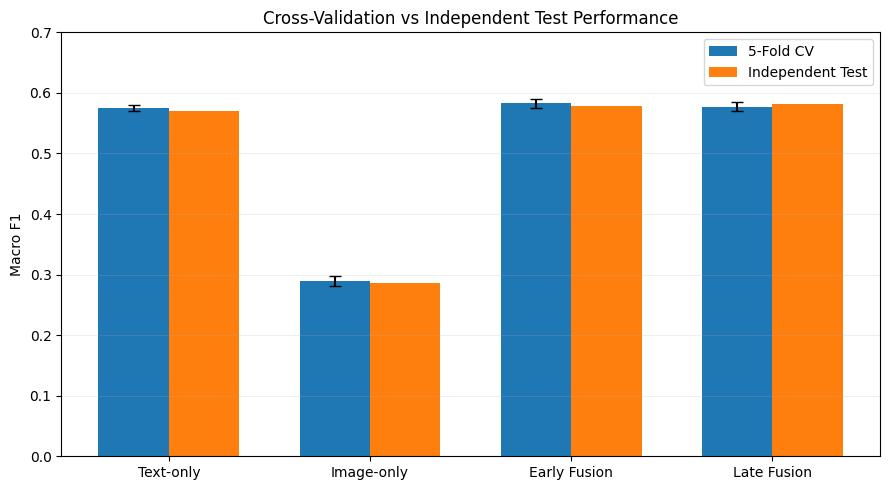


Primary selected model: Early Fusion
Selection basis: Development CV Macro F1

Final evaluation summary: COMPLETED
Report-ready results saved successfully.


In [31]:
# ============================================================
# 11.5. Final Evaluation Summary
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FINAL_DIR = PROJECT_DIR / "results" / "final_evaluation"

# 1. Load cross-validation results
cv_results = pd.read_csv(
    PROJECT_DIR / "results/comparison"
    / "final_model_comparison.csv"
).set_index("Model")

# 2. Load independent test results
test_results = pd.read_csv(
    FINAL_DIR / "independent_test_results.csv"
).set_index("Model")

model_order = [
    "Text-only",
    "Image-only",
    "Early Fusion",
    "Late Fusion"
]

assert set(model_order).issubset(cv_results.index)
assert set(model_order).issubset(test_results.index)

# 3. Combine CV and test metrics
final_summary = pd.DataFrame({
    "Model": model_order,
    "CV Macro F1": cv_results.loc[
        model_order, "Macro F1 Mean"
    ].to_numpy(),
    "CV Macro F1 SD": cv_results.loc[
        model_order, "Macro F1 SD"
    ].to_numpy(),
    "Test Macro F1": test_results.loc[
        model_order, "Macro F1"
    ].to_numpy(),
    "CV Micro F1": cv_results.loc[
        model_order, "Micro F1 Mean"
    ].to_numpy(),
    "Test Micro F1": test_results.loc[
        model_order, "Micro F1"
    ].to_numpy()
})

final_summary["Test - CV Macro F1"] = (
    final_summary["Test Macro F1"]
    - final_summary["CV Macro F1"]
)

print("===== Final Evaluation Summary =====")
print(final_summary.round(4).to_string(index=False))

# 4. Visualise CV vs test Macro F1
x = np.arange(len(model_order))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    final_summary["CV Macro F1"],
    width,
    yerr=final_summary["CV Macro F1 SD"],
    capsize=4,
    label="5-Fold CV"
)

ax.bar(
    x + width / 2,
    final_summary["Test Macro F1"],
    width,
    label="Independent Test"
)

ax.set_xticks(x)
ax.set_xticklabels(model_order)
ax.set_ylabel("Macro F1")
ax.set_ylim(0, 0.7)
ax.set_title(
    "Cross-Validation vs Independent Test Performance"
)
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()

plt.savefig(
    FINAL_DIR / "cv_vs_test_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# 5. Save the final summary
final_summary.to_csv(
    FINAL_DIR / "final_evaluation_summary.csv",
    index=False
)

print("\nPrimary selected model: Early Fusion")
print("Selection basis: Development CV Macro F1")

print("\nFinal evaluation summary: COMPLETED")
print("Report-ready results saved successfully.")